# A Heritage-Led Rejuvenation Strategy for Ya Kun: Analysis Notebook
**NMC5342 Social Media Analytics · Group 2** · JIANG Jingyi, KONG Shuting, LU Chenyue, LU Lingzhi, YAO Xinyan

This notebook contains all the code behind the final report, in the order of the report. Every number quoted in the report is recomputed here and checked with `check()` (✓ = matches the report).

| Notebook part | Report section |
|---|---|
| 0 Setup | – |
| 1 Data collection | 2.1 |
| 2 Cleaning and master table | 2.1 |
| 3 Coding and intercoder reliability | 2.2–2.3, Table 2 |
| 4 Text models: heritage axis, sentiment models, topics | 2.3–2.4, 6.2 |
| 5 Step 1 audit | 3 |
| 6 Step 2 audience | 4 |
| 7 Step 3 + RQ1 | 5 |
| 8 Step 4 + RQ2 | 6 |
| 9 Step 5 + RQ3 | 7 |
| 10 RQ4 | 8 |
| 11 Report figures | Figures 1–10, B1 |
| 12 Summary of checks | – |

**How to run.** Put this notebook in the project folder (the one containing `analysis_outputs/`, `cleaned_data/` and the raw `*.csv` files) and run all cells. New files are written only to `notebook_outputs/`; raw and cleaned files are never overwritten.

**Ethics.** Only public content was collected. API keys are never stored in code (the YouTube key is typed in at run time). Ordinary users are anonymised with salted hashes; only verified or 10k+ follower creators keep their public handle.

## 0 Setup
Packages: `pandas numpy scipy scikit-learn statsmodels matplotlib openpyxl langdetect vaderSentiment textblob afinn`; optional `torch transformers` (Twitter-RoBERTa) and `gensim` (word vectors). Install any that are missing with `%pip install <name>`.

In [1]:
import os, re, json, glob, hashlib, unicodedata, warnings
from pathlib import Path
import numpy as np, pandas as pd
from scipy.stats import mannwhitneyu, kruskal, chi2_contingency, spearmanr
from sklearn.metrics import cohen_kappa_score, roc_auc_score
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

BASE = Path.cwd()                                   # project folder
assert (BASE / "analysis_outputs").exists(), "Run this notebook from the project folder"
AO, CD = BASE / "analysis_outputs", BASE / "cleaned_data"
OUT = BASE / "notebook_outputs"; (OUT / "rebuilt_clean").mkdir(parents=True, exist_ok=True); (OUT / "figures").mkdir(exist_ok=True)

# Optional heavy steps (off by default; saved results are loaded instead)
RUN_COLLECTION   = False                            # calls YouTube / Reddit; needs internet and an API key
REBUILD_CLEANING = os.environ.get("REBUILD_CLEANING", "1") == "1"   # re-runs cleaning from raw files (~2 min)
RUN_ROBERTA      = os.environ.get("RUN_ROBERTA", "0") == "1"        # needs models/pytorch_model.bin (Twitter-RoBERTa)
W2V_PATH         = os.environ.get("W2V_PATH", "")   # Google News word2vec (.kv); not shipped (3.6 GB)
SEED = 5342                                         # used for every sample and model in the project

rd = lambda p, **k: pd.read_csv(p, low_memory=False, **k)

In [2]:
# ---- helpers used throughout ----
CHECKS = []
def check(label, value, expected, tol=0.006):
    # Compare a recomputed value with the number written in the report.
    ok = (abs(float(value) - float(expected)) <= tol) if isinstance(expected, (int, float)) else (str(value) == str(expected))
    CHECKS.append((label, value, expected, "✓" if ok else "✗"))
    print(f"{'✓' if ok else '✗'} {label}: notebook {value} | report {expected}")

def kappa(a, b):
    a, b = pd.Series(a).fillna("NA").astype(str), pd.Series(b).fillna("NA").astype(str)
    return cohen_kappa_score(a, b) if len(set(a) | set(b)) > 1 else np.nan

def ac1(a, b):
    # Gwet's AC1: chance agreement from category prevalence, robust to rare categories
    a, b = list(map(str, a)), list(map(str, b)); cats = sorted(set(a) | set(b)); q = max(len(cats), 2); n = len(a)
    pa = np.mean([x == y for x, y in zip(a, b)]); pi = [(a.count(c) + b.count(c)) / (2 * n) for c in cats]
    pe = sum(p * (1 - p) for p in pi) / (q - 1)
    return (pa - pe) / (1 - pe) if pe < 1 else np.nan

def mwu_p(x, y):
    return mannwhitneyu(pd.Series(x).dropna(), pd.Series(y).dropna(), alternative="two-sided").pvalue

def anon(prefix, s):
    # salted hash: the same user always gets the same id, the name is not recoverable
    return prefix + hashlib.sha1(("yakun5342|" + str(s)).encode()).hexdigest()[:8] if pd.notna(s) and s != "" else ""

## 1 Data collection (report §2.1)
Collected 23–29 October 2026 (Reddit 1 November). Tools:

| Source (dataset code) | Tool | Raw file |
|---|---|---|
| Official IG posts (M2), official TikTok (M3) | Apify Instagram / TikTok scrapers | `ig_official.csv`, `tiktok_official_*.csv` |
| Comments under official posts (M4) | Apify comment scrapers (+ 15 comments embedded per IG post) | `comments_ig.csv`, `comments_tiktok.csv` |
| TikTok user videos (M5) | Apify TikTok search (brand terms + topic hashtags) | `tiktok_ugc_brand.csv`, `tiktok_ugc_topics.csv` |
| Xiaohongshu notes (M6) | Apify Xiaohongshu search, 21 keyword runs | `xhs_*.csv`, `Rednotes_keywords/` |
| Brand24 mentions (M7) | Brand24 export | `ya_kun_report_2026-09-18_08.36.xlsx` |
| Reddit (M10, quotes only) | Apify Reddit scraper (r/singapore) | `returned_1103/Reddit_apify.csv` |
| YouTube videos + comments (M11) | YouTube Data API v3 (code below) | `youtube_videos.csv`, `comments_youtube.csv` |
| Follower audit (M1) | Manual, 24 Oct 2026 | `cleaned_data/platform_overview_clean.csv` |

The YouTube and Reddit collectors are kept here for reproducibility; they only run if `RUN_COLLECTION = True`. The Apify runs were configured in the Apify console (no code).

In [3]:
def collect_youtube(out_dir=BASE):
    # YouTube Data API v3. The key is typed in at run time and never saved.
    import getpass, urllib.request, urllib.parse
    from datetime import datetime, timezone
    KEY = os.environ.get("YT_API_KEY") or getpass.getpass("YouTube API key: ")
    API = "https://www.googleapis.com/youtube/v3/"
    QUERIES = ["ya kun", "ya kun kaya toast", "ya kun soya coffee", "kaya toast singapore", "singapore breakfast", "亚坤"]
    get = lambda ep, **p: json.load(urllib.request.urlopen(API + ep + "?" + urllib.parse.urlencode({**p, "key": KEY}), timeout=30))
    now = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"); hits, videos, comments = {}, [], []
    for q in QUERIES:                                                  # 1) search: top 50 videos per query
        for rank, it in enumerate(get("search", part="snippet", q=q, type="video", maxResults=50, order="relevance")["items"], 1):
            hits.setdefault(it["id"]["videoId"], []).append(f"{q}#{rank}")
    ids = list(hits)
    for i in range(0, len(ids), 50):                                   # 2) video details and statistics
        for v in get("videos", part="snippet,statistics,contentDetails", id=",".join(ids[i:i+50]))["items"]:
            s, st = v["snippet"], v.get("statistics", {})
            videos.append({"video_id": v["id"], "search_terms": "; ".join(hits[v["id"]]), "published_at": s["publishedAt"],
                           "channel_id": s["channelId"], "channel_title": s["channelTitle"], "title": s["title"],
                           "description": s.get("description", ""), "tags": "; ".join(s.get("tags", [])),
                           "duration": v["contentDetails"]["duration"], "views": st.get("viewCount"), "likes": st.get("likeCount"),
                           "comments": st.get("commentCount"), "retrieved_at": now})
    for v in videos:                                                   # 3) top 50 top-level comments per video
        if v["comments"] in (None, "0"): continue
        try: res = get("commentThreads", part="snippet", videoId=v["video_id"], maxResults=50, order="relevance", textFormat="plainText")
        except Exception: continue                                     # comments disabled
        for t in res["items"]:
            c = t["snippet"]["topLevelComment"]["snippet"]
            comments.append({"video_id": v["video_id"], "comment_id": t["id"], "published_at": c["publishedAt"], "author": c["authorDisplayName"],
                             "text": c["textDisplay"], "likes": c["likeCount"], "replies": t["snippet"]["totalReplyCount"], "retrieved_at": now})
    pd.DataFrame(videos).to_csv(out_dir / "youtube_videos.csv", index=False); pd.DataFrame(comments).to_csv(out_dir / "comments_youtube.csv", index=False)

def collect_reddit(out_file=BASE / "reddit_yakun.csv"):
    # Reddit public JSON (polite: 2 s between requests). Final Reddit data came from Apify (returned_1103/Reddit_apify.csv).
    import urllib.request, urllib.parse, time
    UA = {"User-Agent": "NUS-NMC5342-student-project/0.1 (academic research)"}; posts = {}
    for sub in ["singapore", "askSingapore", "SingaporeEats"]:
        for q in ['"ya kun"', "yakun"]:
            url = f"https://www.reddit.com/r/{sub}/search.json?" + urllib.parse.urlencode({"q": q, "restrict_sr": 1, "sort": "new", "limit": 100})
            data = json.load(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=30)); time.sleep(2)
            for c in data["data"]["children"]: posts[c["data"]["id"]] = c["data"]
    pd.DataFrame([{"id": k, "title": p.get("title"), "text": p.get("selftext"), "score": p.get("score")} for k, p in posts.items()]).to_csv(out_file, index=False)

if RUN_COLLECTION:
    collect_youtube(); collect_reddit()

In [4]:
# Raw rows as scraped (before any cleaning)
raw_files = {"IG official posts": "ig_official.csv", "TikTok official (Ya Kun)": "tiktok_official_yakun.csv",
             "TikTok official (competitors)": "tiktok_official_competitors.csv", "IG comments": "comments_ig.csv",
             "TikTok comments": "comments_tiktok.csv", "TikTok UGC (brand terms)": "tiktok_ugc_brand.csv",
             "TikTok UGC (topics)": "tiktok_ugc_topics.csv", "YouTube videos": "youtube_videos.csv",
             "YouTube comments": "comments_youtube.csv", "Reddit (Apify)": "returned_1103/Reddit_apify.csv"}
raw = {k: len(rd(BASE / f)) for k, f in raw_files.items()}
xhs_files = sorted(glob.glob(str(BASE / "xhs_*_general.csv")) + glob.glob(str(BASE / "xhs_*_latest.csv")) + glob.glob(str(BASE / "Rednotes_keywords/*.csv")))
raw["Xiaohongshu (21 keyword runs)"] = sum(len(rd(f)) for f in xhs_files)
raw["Brand24"] = len(pd.read_excel(BASE / "ya_kun_report_2026-09-18_08.36.xlsx", "Mentions", header=1))
raw_tab = pd.Series(raw, name="raw rows"); print(raw_tab.to_string()); print("Total raw rows scraped:", raw_tab.sum())

IG official posts                1142
TikTok official (Ya Kun)           31
TikTok official (competitors)     414
IG comments                      1538
TikTok comments                    47
TikTok UGC (brand terms)          791
TikTok UGC (topics)               558
YouTube videos                    246
YouTube comments                 4061
Reddit (Apify)                    275
Xiaohongshu (21 keyword runs)     420
Brand24                          2210
Total raw rows scraped: 11733


## 2 Cleaning and master table (report §2.1)
Each source is cleaned by one function (originally `scripts/*_clean.py`). Common rules:
- **De-duplication** (same post found by several queries; same author posting the same text).
- **Relevance**: must mention Ya Kun with food context, or be category content (kaya toast, kopi, Singapore breakfast); name clashes such as *yacon*, *Fayakun* or 蔡徐坤 are removed.
- **Spam / bots**: pure emoji, tag-only and link-spam comments removed; accounts commenting under ≥ 20 posts are flagged (`suspected_bot`) and checked by hand.
- **Non-consumer accounts**: brand, franchise, media and commercial accounts are flagged, then excluded from user analyses.
- **Windows**: official posts 1 Jul 2024 – 25 Oct 2026; posts from the last 7 days are kept but not used for engagement (counts still rising).
- **Anonymisation** and **translation**: non-English text was translated into English by Claude (local words such as kaya, kopi, dabao kept) and stored in `cleaned_data/translations_en.csv`; it is merged as `text_en`.

`REBUILD_CLEANING = True` re-runs every cleaning step from the raw files into `notebook_outputs/rebuilt_clean/` and checks that the row counts equal the cleaned files used in the analysis.

In [5]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0
def lang(s):
    s = re.sub(r"https?://\S+|#\S+|@\S+", " ", str(s))
    if sum(ch.isalpha() for ch in s) < 3: return "unknown"
    try: return detect(s)
    except Exception: return "unknown"
num = lambda s: pd.to_numeric(s, errors="coerce")
has_word = lambda s: any(unicodedata.category(ch)[0] in "LN" for ch in str(s))
SCRAPE = pd.Timestamp("2026-10-25", tz="UTC")
BRAND_RX = re.compile(r"ya ?kun|亚坤|亞坤", re.I)
# keyword cues used later only as descriptive flags (never as coded variables)
TOURIST = re.compile(r"first time|1st time|first visit|visit(?:ing|ed)? singapore|trip to singapore|in singapore for|travel|tourist|holiday|vacation|must[- ]?(?:try|eat|visit|have)|bucket list|layover|itinerary|next time (?:i|we)|days? in singapore|singapore (?:vlog|travel|guide|trip)|#sgtravel|打卡|攻略|旅游|旅遊|旅行|第一次|必吃|必試|必试|游客|遊客|自由行", re.I)
LOCAL = re.compile(r"\blah\b|\bleh\b|\bsia\b|\bshiok\b|\bdabao\b|\bkosong\b|kopitiam|grew up|growing up|childhood|since young|since (?:i was )?(?:a )?kid|my (?:grand(?:pa|ma|father|mother)|ah ?ma|ah ?gong)|every morning|old days|memories|nostalgi|as a singaporean|小时候|小時候|从小|從小|本地人|新加坡人", re.I)
SOYA = re.compile(r"soya|soy ?(?:milk|latte|coffee)|豆浆|豆奶|豆漿", re.I)
PRICE = re.compile(r"\$\s?\d|\bprice|pricey|expensive|cheap|afford|worth|overpriced|value for money|贵|貴|便宜|价格|價格|划算", re.I)

In [6]:
# ---- 2.1 Official posts (M2 Instagram, M3 TikTok) -> official_posts_clean ----
BRANDS = {"yakunkayatoastsg": "Ya Kun", "toastboxsg": "Toast Box", "toastboxsingapore": "Toast Box",
          "oldchangkeesingapore": "Old Chang Kee", "arabicasg": "% Arabica"}
def clean_official():
    START, CUT7, SIX = pd.Timestamp("2024-07-01", tz="UTC"), SCRAPE - pd.Timedelta(days=7), SCRAPE - pd.DateOffset(months=6)
    ig = rd(BASE / "ig_official.csv"); ig["account"] = ig.inputUrl.str.extract(r"instagram\.com/([^/]+)/")[0]
    co = [c for c in ig.columns if re.fullmatch(r"coauthorProducers/\d+/username", c)]
    ig["coauthors"] = ig[co].apply(lambda r: "; ".join(r.dropna().astype(str)), axis=1)
    likes = num(ig.likesCount)
    I = pd.DataFrame({"platform": "Instagram", "brand": ig.account.map(BRANDS), "post_id": ig.id.astype(str), "url": ig.url,
        "published": pd.to_datetime(ig.timestamp, utc=True), "format": ig.type.map({"Video": "reel_video", "Image": "image", "Sidecar": "carousel"}),
        "caption": ig.caption.fillna(""), "is_coauthor_post": (ig.ownerUsername != ig.account) | (ig.coauthors != ""),
        "likes": likes.where(likes >= 0), "likes_hidden": likes < 0, "comments": num(ig.commentsCount), "shares": np.nan, "saves": np.nan,
        "views": num(ig.videoPlayCount).fillna(num(ig.videoViewCount))})
    I["engagement"] = (I.likes.fillna(0) + I.comments.fillna(0)).where(~I.likes_hidden)      # IG: likes + comments; hidden likes -> missing
    tt = pd.concat([rd(BASE / f) for f in ["tiktok_official_yakun.csv", "tiktok_official_competitors.csv"]], ignore_index=True)
    T = pd.DataFrame({"platform": "TikTok", "brand": tt.input.map(BRANDS), "post_id": tt.id.astype(str), "url": tt.webVideoUrl,
        "published": pd.to_datetime(tt.createTimeISO, utc=True), "format": tt.isSlideshow.map({True: "slideshow", False: "video"}).fillna("video"),
        "caption": tt.text.fillna(""), "is_coauthor_post": False, "likes": num(tt.diggCount), "likes_hidden": False,
        "comments": num(tt.commentCount), "shares": num(tt.shareCount), "saves": num(tt.collectCount), "views": num(tt.playCount)})
    T["engagement"] = T[["likes", "comments", "shares", "saves"]].fillna(0).sum(axis=1)           # TikTok: + shares + saves
    P = pd.concat([I, T], ignore_index=True).drop_duplicates(["platform", "post_id"])
    P = P[(P.published >= START) & (P.published <= SCRAPE + pd.Timedelta(days=1))].copy()
    P["published_date"] = P.published.dt.strftime("%Y-%m-%d"); P["recent_7d"] = P.published > CUT7
    P["last_6m"] = (P.published >= SIX) & ~P.recent_7d; P["use_for_engagement"] = ~P.recent_7d & P.engagement.notna()
    P["caption_lang"] = P.caption.apply(lang)
    return P.drop(columns="published")

In [7]:
# ---- 2.2 Comments under official posts (M4) ----
def clean_comments(P):
    P = P.copy(); P["key"] = P.url.str.extract(r"/(?:p|reel|video)/([^/?]+)")[0]
    ig = rd(BASE / "comments_ig.csv"); ig = ig[ig.error.isna()]
    I = pd.DataFrame({"platform": "Instagram", "key": ig.postUrl.str.extract(r"/(?:p|reel)/([^/]+)")[0], "comment_id": ig.id.astype(str),
                      "published": ig.timestamp, "author": ig.ownerUsername, "text": ig.text.fillna("").astype(str), "likes": ig.likesCount})
    og = rd(BASE / "ig_official.csv"); emb = []                                    # up to 15 comments embedded in each post record
    for n in range(15):
        pre = f"latestComments/{n}/"
        if pre + "id" not in og: break
        e = og[["shortCode", pre + "id", pre + "timestamp", pre + "ownerUsername", pre + "text", pre + "likesCount"]].dropna(subset=[pre + "id"])
        e.columns = ["key", "comment_id", "published", "author", "text", "likes"]; emb.append(e)
    E = pd.concat(emb, ignore_index=True); E["platform"] = "Instagram"; E["text"] = E.text.fillna("").astype(str)
    for d in (I, E): d["comment_id"] = num(d.comment_id).astype("Int64").astype(str)
    I = pd.concat([I, E], ignore_index=True).drop_duplicates(["platform", "comment_id"])
    tt = rd(BASE / "comments_tiktok.csv", dtype={"cid": str})
    T = pd.DataFrame({"platform": "TikTok", "key": tt.videoWebUrl.str.extract(r"/video/(\d+)")[0], "comment_id": tt.cid,
                      "published": tt.createTimeISO, "author": tt.uniqueId, "text": tt.text.fillna("").astype(str), "likes": tt.diggCount})
    C = pd.concat([I, T], ignore_index=True).merge(P[["platform", "key", "brand", "post_id"]], on=["platform", "key"], how="inner")  # posts in window only
    C["text"] = C.text.str.replace(r"\s+", " ", regex=True).str.strip()
    C = C[C.text.apply(has_word) & ~C.text.str.fullmatch(r"(?:@[\w.]+[\s,]*)+")]      # drop pure emoji and tag-only comments
    C = C.drop_duplicates(["author", "text"])                                         # same person, same text on several posts
    C["is_brand_account"] = C.author.isin(BRANDS)
    C["suspected_bot"] = C.groupby("author").key.transform("nunique") >= 20
    C["author_anon"] = C.author.apply(lambda s: anon("u_", s)); C["text"] = C.text.str.replace(r"@[\w.\-]+", "@user", regex=True)
    return C.drop(columns=["author", "key"])

In [8]:
# ---- 2.3 TikTok user videos (M5) ----
def clean_tiktok_ugc():
    b = rd(BASE / "tiktok_ugc_brand.csv"); t = rd(BASE / "tiktok_ugc_topics.csv"); d = pd.concat([b, t], ignore_index=True)
    d["hashtags"] = d.filter(regex=r"^hashtags/\d+/name$").fillna("").astype(str).agg(lambda r: " ".join(x for x in r if x), axis=1)
    d["all"] = d.text.fillna("").astype(str) + " " + d.hashtags
    d = d.drop_duplicates("id").copy()
    NOISE = re.compile(r"yacon|yacón|faya ?kun|kun ?faya|liyakun|亚坤(西刀)?鱼丸|ယာကွန်", re.I)
    FOOD = re.compile(r"kaya|toast|kopi|coffee|egg|singapor|\bsg\b|breakfast|outlet|cafe|café|\bteh\b|food|bread|roti|soya|toastwich|cookie|mooncake|吐司|咖椰|咖啡|早餐|新加坡|面包|麵包|ขนมปัง|สังขยา", re.I)
    KAYA = re.compile(r"kaya|咖椰|加椰|สังขยา", re.I); SOYAKOPI = re.compile(r"kopi ?soya|soya ?kopi|teh ?soya|soya ?teh|kopi ?c? ?soy", re.I)
    TRAD = re.compile(r"kopi|kopitiam|soft[- ]?boil|half[- ]?boil|hawker|traditional breakfast|local breakfast|breakfast set|toast", re.I)
    SG = re.compile(r"singapor|\bsg\b|🇸🇬|新加坡|#sgfood|#sgeats", re.I)
    def relevance(s):
        if BRAND_RX.search(NOISE.sub(" ", s)) and FOOD.search(s): return "yakun_text"
        if KAYA.search(s) or SOYAKOPI.search(s) or (SOYA.search(s) and SG.search(s)) or (TRAD.search(s) and SG.search(s)) or (SG.search(s) and re.search(r"breakfast|早餐", s, re.I)):
            return "category"
        return "off_topic"
    d["relevance"] = d["all"].apply(relevance); d = d[d.relevance != "off_topic"]
    fans = num(d["authorMeta/fans"])
    out = pd.DataFrame({"video_id": d.id.astype(str), "relevance": d.relevance, "published_date": pd.to_datetime(d.createTimeISO, utc=True).dt.strftime("%Y-%m-%d"),
        "author_anon": d["authorMeta/name"].apply(lambda s: anon("u_", s)), "author_fans": fans, "lang": d.textLanguage,
        "format": d.isSlideshow.map({True: "slideshow", False: "video"}).fillna("video"), "duration_sec": num(d["videoMeta/duration"]),
        "views": num(d.playCount), "likes": num(d.diggCount), "comments": num(d.commentCount), "shares": num(d.shareCount), "saves": num(d.collectCount)})
    out["engagement"] = out[["likes", "comments", "shares", "saves"]].fillna(0).sum(axis=1)
    out["tourist_cue"] = d["all"].str.contains(TOURIST).values
    return out

In [9]:
# ---- 2.4 YouTube videos and comments (M11) ----
def clean_youtube():
    v = rd(BASE / "youtube_videos.csv", dtype=str, encoding="utf-8-sig").fillna(""); c = rd(BASE / "comments_youtube.csv", dtype=str, encoding="utf-8-sig").fillna("")
    NOISE = re.compile(r"yacon|ubi ?yak[ou]n|faya ?kun|kun ?faya|liyakun|kutilmagan|sardor|shoxruz|亚坤(西刀)?鱼丸|亞坤(西刀)?魚丸", re.I)
    KAYA = re.compile(r"kaya|咖椰|加椰", re.I); SG = re.compile(r"singapor|\bsg\b|🇸🇬|新加坡", re.I)
    TRAD = re.compile(r"kopi|kopitiam|soft[- ]?boil|half[- ]?boil|hawker|traditional breakfast|local breakfast|heritage breakfast|breakfast set|coffee ?shop|toast|soya coffee|kopi soya", re.I)
    HOTEL = re.compile(r"buffet|shangri|swiss[oô]tel|pan pacific|hotel|platinum", re.I)
    brand = lambda s: bool(BRAND_RX.search(s)) and not NOISE.search(s)
    def relevance(r):
        t, ti = r.title + " " + r.description + " " + r.tags, r.title
        if NOISE.search(t) and not brand(NOISE.sub(" ", t)): return "noise"
        if brand(ti): return "yakun_title"
        if brand(t): return "yakun_mention"
        if KAYA.search(t) or (TRAD.search(t) and SG.search(t)) or (SG.search(t) and re.search(r"breakfast|早餐", t, re.I) and not HOTEL.search(ti)): return "category"
        return "off_topic"
    v["relevance"] = v.apply(relevance, axis=1); v = v[~v.relevance.isin(["noise", "off_topic"])]
    c = c[c.video_id.isin(v.video_id)].copy(); c["text"] = c.text.str.replace(r"\s+", " ", regex=True).str.strip()
    spam = c.text.str.contains(r"https?://|www\.", case=False) & c.text.str.contains(r"subscri|my channel|check (?:out )?my|whatsapp|telegram|crypto|invest|earn", case=False)
    c = c[c.text.apply(has_word) & ~spam].drop_duplicates(["author", "text"])
    c["author_anon"] = c.author.apply(lambda s: anon("u_", s)); c = c.drop(columns="author")
    return v, c

In [10]:
# ---- 2.5 Xiaohongshu (M6): first 9 searches + 12 extra keyword runs, merged ----
def clean_xhs():
    cols = ["id", "keyword", "sortSource", "title", "desc", "type", "timestamp", "author/userid", "engagement/liked_count",
            "engagement/collected_count", "engagement/comments_count", "engagement/shared_count", "url"]
    raw = pd.concat([rd(f, usecols=lambda c: c in cols, dtype={"id": str, "author/userid": str}) for f in xhs_files], ignore_index=True)
    raw["src"] = raw.keyword.astype(str)
    agg = {c: "first" for c in raw.columns if c not in ("id", "src")}; agg["src"] = lambda s: "; ".join(dict.fromkeys(s))
    d = raw.groupby("id", as_index=False).agg(agg)
    CAT = re.compile(r"咖椰|加椰|kaya|吐司|土司|国民早餐|國民早餐|豆浆咖啡|豆奶咖啡|早餐|早午餐|brunch|kopi", re.I)
    XBRAND = re.compile(r"ya ?kun|亚坤|亞坤|雅坤", re.I)
    text = (d.title.fillna("") + " " + d.desc.fillna("")).str.strip(); brand_q = d.src.str.contains("亚坤|亞坤")
    rel = ["yakun_text" if XBRAND.search(t) else "possible_yakun" if (q and CAT.search(t)) else "category" if not q else "irrelevant" for t, q in zip(text, brand_q)]
    # manual judgements after reading the notes (30 Oct): two notes are clearly Ya Kun without naming it; three are not Ya Kun
    OVERRIDE = {"6acdb00f000000001b0225ff": "yakun_inferred", "6ad645f00000000027014a34": "yakun_inferred", "6adf38d4000000001601ad72": "category",
                "6ae07880000000001a0135d8": "irrelevant", "6ae06f29000000001902791e": "irrelevant"}
    d["relevance"] = [OVERRIDE.get(i, r) for i, r in zip(d.id, rel)]; d["text"] = text
    d["engagement"] = sum(num(d[c]).fillna(0) for c in cols[8:12])
    return d.rename(columns={"id": "note_id", "src": "search_terms"})

In [11]:
# ---- 2.6 Brand24 (M7) ----
def clean_brand24():
    df = pd.read_excel(BASE / "ya_kun_report_2026-09-18_08.36.xlsx", "Mentions", header=1).iloc[:, 1:]
    df["text"] = (df.Title.fillna("") + " " + df.Content.fillna("")).str.strip(); t = df.text.str.lower()
    loose = t.str.contains(r"ya ?kun|yakun") & t.str.contains(r"kaya|toast|kopi|coffee|egg|singapore|\bsg\b|breakfast|outlet|cafe|pie|mall|teh")
    strict = t.str.contains(r"ya ?kun kaya|yakun kaya|#\s?yakun|@yakun|ya kun (?:coffee|cafe|outlet|kopi|toast|set|far east|jurong)")
    noise = t.str.contains(r"lam yakun|fayakun|kun fa|yakun lahu|ya kun mah|ya kun mau|cerita bahasa indramayu|ceramah|kh hasan|sandiwara|wa kosim|raden chulaeng|misteri rangdu|kopiane mbah|nyandarua|ayblar|winora|tarling|full album|dikawin|pelet|yakun topdi|bauchi|fresh yakun|yakun sayang|hilman fauzi|xe đụng|hikoya")
    d = df[(loose | strict) & ~noise].drop_duplicates("text").copy()
    def src(r):   # source type by regex on text + domain (not hand-checked; see limitations)
        x, dm = r.text.lower(), str(r.Domain)
        if re.search(r"thrills singaporeans|delights singaporeans|comment on|comentario|commenti|komentar|تعليق|hozzászólása", x): return "spam"
        if re.search(r"yakunmyanmar|yakun_indonesia|yakun\.com", x + dm): return "brand_or_franchise"
        if re.search(r"promo|promotion|diskon|giveaway|deals|onsales|syioknya|free ", x + dm): return "promo_site"
        if re.search(r"mall|directory|hotel|changiairport|junction8|313somerset|amazon|tour packages|atamed|amk hub|moe\.edu|townsquare", x + dm) and not re.search(r"youtube|reddit", dm): return "commercial_listing"
        if re.search(r"stomp|wikipedia|tnp|oldest restaurants|foodification|drinkjournal", x + dm): return "news_media"
        if re.search(r"itinerary|guide|layover guide|days in|walking|dishes to try|tour|vietdaily|hanoi|eranet|trotterz|magictrips|cravejourney|culturedwanderer|mimi|rebeccaandtheworld|hollandvillage|merlion", x + dm) and not re.search(r"youtube|tiktok|reddit|naver", dm): return "travel_site"
        return "ordinary_user"
    d["source_type"] = d.apply(src, axis=1)
    return d

In [12]:
# ---- run the rebuild and compare with the cleaned files used in the analysis ----
stored = {"official posts": rd(CD / "official_posts_clean.csv", dtype={"post_id": str}), "official-post comments": rd(CD / "comments_official_clean.csv"),
          "TikTok UGC": rd(CD / "tiktok_ugc_clean.csv"), "YouTube videos": rd(CD / "youtube_videos_clean.csv"),
          "YouTube comments": rd(CD / "comments_youtube_clean.csv"), "Brand24": rd(CD / "brand24_cleaned.csv")}
xm = rd(CD / "xhs_notes_merged_1102.csv")
if REBUILD_CLEANING:
    P_new = clean_official(); C_new = clean_comments(P_new); U_new = clean_tiktok_ugc(); YV_new, YC_new = clean_youtube()
    X_new = clean_xhs(); B_new = clean_brand24()
    rebuilt = {"official posts": P_new, "official-post comments": C_new, "TikTok UGC": U_new, "YouTube videos": YV_new,
               "YouTube comments": YC_new, "Brand24": B_new}
    for k, v in rebuilt.items(): v.to_csv(OUT / "rebuilt_clean" / f"{k.replace(' ', '_')}.csv", index=False, encoding="utf-8-sig")
    X_new.to_csv(OUT / "rebuilt_clean" / "xiaohongshu_merged.csv", index=False, encoding="utf-8-sig")
    cmp = pd.DataFrame({"raw rows": [raw.get(k) for k in ["IG official posts", "IG comments", "TikTok UGC (brand terms)", "YouTube videos", "YouTube comments", "Brand24"]],
                        "rebuilt": [len(rebuilt[k]) for k in stored], "stored cleaned file": [len(stored[k]) for k in stored]}, index=list(stored))
    print(cmp.to_string())
    for k in stored: check(f"cleaning reproduces {k}", len(rebuilt[k]), len(stored[k]), tol=0)
    print("Xiaohongshu relevance (rebuilt):", X_new.relevance.value_counts().to_dict(), "| stored:", xm.relevance.value_counts().to_dict())
    check("Xiaohongshu notes kept (not irrelevant)", int((X_new.relevance != "irrelevant").sum()), int((xm.relevance != "irrelevant").sum()), tol=0)

                        raw rows  rebuilt  stored cleaned file
official posts              1142     1425                 1425
official-post comments      1538     2171                 2171
TikTok UGC                   791      562                  562
YouTube videos               246      192                  192
YouTube comments            4061     2740                 2740
Brand24                     2210       97                   97
✓ cleaning reproduces official posts: notebook 1425 | report 1425
✓ cleaning reproduces official-post comments: notebook 2171 | report 2171
✓ cleaning reproduces TikTok UGC: notebook 562 | report 562
✓ cleaning reproduces YouTube videos: notebook 192 | report 192
✓ cleaning reproduces YouTube comments: notebook 2740 | report 2740
✓ cleaning reproduces Brand24: notebook 97 | report 97
Xiaohongshu relevance (rebuilt): {'yakun_text': 180, 'irrelevant': 51, 'category': 44, 'possible_yakun': 18, 'yakun_inferred': 2} | stored: {'yakun_text': 180, 'irrelevant'

**Data used in the report (Table 1).** "Collected" in the report means items that passed the relevance and duplicate filters above, plus the 275 raw Reddit rows. The quantitative master table (`master_scored.csv`) holds 7,317 items. It uses the first Xiaohongshu set (130 notes, before the 1 Nov extra keyword runs); the merged 244-note set is used only for the RQ4 description, and Reddit only for quotes.

In [13]:
P, CM = stored["official posts"], stored["official-post comments"]   # CM, not C: C() is the regression formula's category function
U, YV, YC, B24 = stored["TikTok UGC"], stored["YouTube videos"], stored["YouTube comments"], stored["Brand24"]
R = rd(BASE / "returned_1103/Reddit_apify.csv"); X244 = xm[xm.relevance != "irrelevant"]
table1 = pd.Series({"Owned: Ya Kun posts": (P.brand == "Ya Kun").sum(), "Owned: competitor posts": (P.brand != "Ya Kun").sum(),
    "Earned on owned: comments on Ya Kun posts": (CM.brand == "Ya Kun").sum(), "Earned on owned: comments on competitor posts": (CM.brand != "Ya Kun").sum(),
    "Earned: TikTok user videos": len(U), "Earned: YouTube videos": len(YV), "Earned: YouTube comments": len(YC),
    "Earned: Xiaohongshu notes": len(X244), "Earned: Brand24 mentions": len(B24), "Earned: Reddit (quotes only)": len(R)})
print(table1.to_string()); total = int(table1.sum()); print("Total:", total)
check("Owned media (Table 1)", table1.iloc[:2].sum(), 1425, 0); check("Earned on owned channels", table1.iloc[2:4].sum(), 2171, 0)
check("Earned media", table1.iloc[4:].sum(), 4110, 0); check("Total collected", total, 7706, 0)
M = rd(AO / "master_scored.csv"); check("Items in quantitative analysis", len(M), 7317, 0)
print(M.dataset.value_counts().to_string())

Owned: Ya Kun posts                               256
Owned: competitor posts                          1169
Earned on owned: comments on Ya Kun posts         515
Earned on owned: comments on competitor posts    1656
Earned: TikTok user videos                        562
Earned: YouTube videos                            192
Earned: YouTube comments                         2740
Earned: Xiaohongshu notes                         244
Earned: Brand24 mentions                           97
Earned: Reddit (quotes only)                      275
Total: 7706
✓ Owned media (Table 1): notebook 1425 | report 1425
✓ Earned on owned channels: notebook 2171 | report 2171
✓ Earned media: notebook 4110 | report 4110
✓ Total collected: notebook 7706 | report 7706
✓ Items in quantitative analysis: notebook 7317 | report 7317
dataset
M11 YouTube comments         2740
M4 official-post comments    2171
M2/M3 official posts         1425
M5 TikTok UGC                 562
M11 YouTube videos            192
M6 Xiaoh

### 2.7 Master table and automatic scores
`master_table.csv` stacks all cleaned sources with common columns (`uid`, `dataset`, `content_type`, `author_type`, `yakun_related`, `industry`, `text_en`, engagement). `master_scored.csv` adds, for every `text_en`:
- the **seed-word heritage axis** (`h_valence`; SemAxis on Google News word2vec, 15 heritage vs 17 novelty seed words, see `seed_words_v1.csv`),
- **vMFD** loyalty and authority valence (course vec-tionary, Duan et al., 2025),
- **VADER** sentiment.

These need the 3.6 GB word2vec file and the `vMFD` package, so the scoring code is shown but runs only if `W2V_PATH` is set.

In [14]:
# Building the word-vector file used by the heritage axis (not run here: downloads 1.6 GB, file 3.6 GB unpacked).
# Google News word2vec (Mikolov et al., 2013), 3 million words x 300 dimensions; we keep the 500,000 most frequent words.
# To run: set BUILD_W2V = True, then set W2V_PATH to the saved file and re-run Parts 2.7 and 4.2.
BUILD_W2V = False
def build_w2v(out=BASE / "w2v_500k.kv"):
    import gensim.downloader as api                                     # pip install gensim
    full = api.load("word2vec-google-news-300")                          # KeyedVectors, 3M words
    small = type(full)(vector_size=full.vector_size)
    words = full.index_to_key[:500_000]                                  # sorted by frequency
    small.add_vectors(words, full[words]); small.save(str(out))
    return out
if BUILD_W2V:
    W2V_PATH = str(build_w2v())

In [15]:
# Rebuild the master table from the cleaned files and compare with the stored one
MT = rd(AO / "master_table.csv")
check("master_table rows", len(MT), 7317, 0); check("master_scored has the same uids", int(MT.uid.isin(M.uid).sum()), 7317, 0)

def score_master(master, w2v_path):
    # Original scoring (scripts/analysis/score_all.py): seed-axis heritage + vMFD + VADER
    from gensim.models import KeyedVectors; from gensim.parsing.preprocessing import STOPWORDS
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer; import vMFD
    wv = KeyedVectors.load(w2v_path); S = rd(BASE / "seed_words_v1.csv"); S = S[S.status == "keep"]
    u = lambda w: wv[w] / np.linalg.norm(wv[w])
    A = np.mean([u(w) for w in S[S.side == "heritage"].word], 0) - np.mean([u(w) for w in S[S.side == "novelty"].word], 0); A /= np.linalg.norm(A)
    stop = set(STOPWORDS) | {"ya", "kun", "yakun", "kaya", "toast", "singapore", "sg"}       # brand words would dominate every post
    toks = lambda s: [w for w in re.sub(r"[^a-z\s]", " ", re.sub(r"http\S+|@\S+", " ", str(s)).lower()).split() if w not in stop and w in wv]
    master["h_valence"] = master.text_en.apply(lambda s: np.mean([u(w) @ A for w in toks(s)]) if toks(s) else np.nan)
    vo, sia = vMFD.vMFD(), SentimentIntensityAnalyzer()
    master["loyalty_valence"] = master.text_en.apply(lambda s: vo.calculate_metrics(" ".join(toks(s)))["valence"]["loyalty"])
    master["vader_compound"] = master.text_en.apply(lambda s: sia.polarity_scores(str(s))["compound"])
    return master
if W2V_PATH: score_master(MT.copy(), W2V_PATH)

✓ master_table rows: notebook 7317 | report 7317
✓ master_scored has the same uids: notebook 7317 | report 7317


## 3 Coding and intercoder reliability (report §2.2–2.3, Table 2)
**Codebook** (summary in report Appendix A): heritage meanings H1 founding story, H2 traditional craft, H3 personal memory, H4 Singapore identity, H5 kopitiam culture; novelty tactics Y1 trend format, Y2 collaboration, Y3 new product, Y4 merchandise, Y5 creator/celebrity, Y6 interactive; user codes A1 relevance, F sentiment (F1 positive, F2 neutral, F3 negative, F4 mixed), E perceived as dated, N other draws; G tourist orientation (content cues only).

**LLM coding.** Claude coded every post with the codebook (`analysis_outputs/ai_precode_*.csv`; heritage yes/no for all 641 official posts in `heritage_二元编码_官方帖641_1103.csv`). Its answers were saved **before** the coders started.

**Samples** (seed 5342): V1 = 50 Ya Kun posts, V2 = 30 competitor posts (10 per brand), V3 = 60 user posts stratified by source, 120 posts for the heritage yes/no check, 100 user posts for the tourist-orientation gate. Top posts for Steps 3 and 5 (20 + 30) were coded fully by two members; where they disagreed, the final code is one of the two coders' answers (never an LLM answer), and κ is computed on the original codes.

Rule: keep a code if Cohen's κ ≥ 0.6 (Landis & Koch, 1977); Gwet's AC1 reported alongside.

In [16]:
import openpyxl
RET = BASE / "returned_1103"
def load_sheet(f, sheet):
    # coder workbooks: row 1 = instructions, row 2 = headers, row 3 = example
    rows = list(openpyxl.load_workbook(RET / f, read_only=True, data_only=True)[sheet].iter_rows(values_only=True))
    h = list(rows[1]); return pd.DataFrame([r[:len(h)] for r in rows[2:] if r and r[0] and r[0] != "示例"], columns=h).set_index(h[0])
is1 = lambda v: 1 if str(v).strip() in ("1", "1.0") else 0
F_REMAP = {"F1": "F1", "F2": "F3", "F3": "F4", "F4": "F2"}       # member 1 used an older sheet with a different F order
def human_codes(D, remap=False):
    out = pd.DataFrame(index=D.index)
    for c in D.columns:
        m = re.match(r"^(H[1-5]|Y[1-6]|N[1-6]) ", str(c))
        if m: out[m.group(1)] = D[c].apply(is1)
    if "F 情感" in D: out["F"] = D["F 情感"].map(F_REMAP) if remap else D["F 情感"]
    out["anyY"] = out[[f"Y{i}" for i in range(1, 7)]].max(axis=1) if "Y1" in out else np.nan
    return out

In [17]:
# 3.1 Heritage yes/no: two coders on 120 posts, and the LLM against each coder
wb = openpyxl.load_workbook(RET / "heritage_labeling_v2_AB.xlsx", data_only=True)
def coder(s):
    r = list(wb[s].iter_rows(min_row=2, values_only=True)); return pd.DataFrame([x[:4] for x in r if x[0] is not None], columns=["编号", "platform", "text", "h"]).set_index("编号").h
key = rd(AO / "heritage_labeling_key_v2.csv").set_index("编号")
HL = key.join(coder("Coder_A").rename("A")).join(coder("Coder_B").rename("B")).dropna(subset=["A", "B"])
HL["A"], HL["B"] = HL.A.astype(int), HL.B.astype(int)
print("n =", len(HL), "| agree:", (HL.A == HL.B).sum())
check("Heritage κ coder vs coder", round(kappa(HL.A, HL.B), 2), 0.84)
check("Heritage: items both coders agree on (test set)", int((HL.A == HL.B).sum()), 112, 0)
# LLM blind test: Claude labelled the same 120 texts without seeing the coders' answers (saved before comparison)
x = HL.join(rd(AO / "heritage_AI盲测120_1103.csv").set_index("编号").AI)
kA, kB = kappa(x.A, x.AI), kappa(x.B, x.AI); print(f"LLM vs coder A κ={kA:.2f}, vs coder B κ={kB:.2f} (n={len(x)})")
check("Heritage κ AI vs coders (max)", round(max(kA, kB), 2), 0.77); check("Heritage κ AI vs coders (min)", round(min(kA, kB), 2), 0.72)

n = 120 | agree: 112
✓ Heritage κ coder vs coder: notebook 0.84 | report 0.84
✓ Heritage: items both coders agree on (test set): notebook 112 | report 112
LLM vs coder A κ=0.77, vs coder B κ=0.72 (n=120)
✓ Heritage κ AI vs coders (max): notebook 0.77 | report 0.77
✓ Heritage κ AI vs coders (min): notebook 0.72 | report 0.72


In [18]:
# 3.2 Novelty: overall code fails, single tactics kept (V1 = 50 Ya Kun posts, members 5 and 2)
V1A = human_codes(load_sheet("coding_v2_组员5.xlsx", "V1_官方帖50")); V1B = human_codes(load_sheet("coding_v2_组员2.xlsx", "V1_官方帖50")).reindex(V1A.index)
check("Novelty (any of 6 tactics) κ coder vs coder", round(kappa(V1A.anyY, V1B.anyY), 2), 0.39)
# finalised human codes = agreed codes + the coders' joint decision on disagreements (coding_sheets/V1_年轻化分歧_组员5组员2.xlsx)
FIN = rd(AO / "V1_新潮手法_人工定稿_1103.csv").set_index("uid（勿改）")
AIY = rd(AO / "ai_precode_yakun_official.csv").set_index("uid").C_youth.reindex(FIN.index).fillna("")
for code_, name, rep in [("Y2", "collaborations", 0.81), ("Y3", "new products", 0.65), ("Y4", "merchandise", 0.73)]:
    check(f"{name} κ AI vs finalised human codes", round(kappa(FIN[code_], AIY.str.contains(fr"\b{code_}\b").astype(int)), 2), rep)

✓ Novelty (any of 6 tactics) κ coder vs coder: notebook 0.39 | report 0.39
✓ collaborations κ AI vs finalised human codes: notebook 0.81 | report 0.81
✓ new products κ AI vs finalised human codes: notebook 0.65 | report 0.65
✓ merchandise κ AI vs finalised human codes: notebook 0.73 | report 0.73


In [19]:
# 3.3 Tourist orientation gate (100 user posts; members 1 and 2): ≥60% judgeable and κ ≥ 0.7
# Codes: T1 tourist-oriented, T2 local, T3 eating at an overseas outlet, T0 cannot tell (identity cues in the content only)
G = rd(AO / "RQ4_最终编码_草稿.csv").set_index("uid（勿改）")
G["author_type"] = rd(AO / "master_scored.csv", usecols=["uid", "author_type"]).set_index("uid").author_type.reindex(G.index)
for c in ["组员1 G", "组员2 G"]:
    s = G[c].dropna(); print(f"{c}: coded {len(s)}, judgeable (not T0) {s.ne('T0').mean():.0%}, tourist/local (T1/T2) {s.isin(['T1', 'T2']).mean():.0%}")
both = G[G["组员1 G"].notna() & G["组员2 G"].notna() & G.author_type.isin(["user", "creator"])]   # brand / media posts removed
print("coded by both (user posts):", len(both))
check("Tourist orientation κ, tourist-oriented vs not (n=56)", round(kappa(both["组员1 G"].eq("T1"), both["组员2 G"].eq("T1")), 2), 0.73)
print("κ on all four codes:", round(kappa(both["组员1 G"], both["组员2 G"]), 2))
judgeable = np.mean([G[c].dropna().ne("T0").mean() for c in ["组员1 G", "组员2 G"]])
check("Tourist orientation: share judgeable (mean of two coders)", round(judgeable, 2), 0.64)

组员1 G: coded 63, judgeable (not T0) 63%, tourist/local (T1/T2) 37%
组员2 G: coded 89, judgeable (not T0) 79%, tourist/local (T1/T2) 58%
coded by both (user posts): 56
✓ Tourist orientation κ, tourist-oriented vs not (n=56): notebook 0.73 | report 0.73
κ on all four codes: 0.46
✗ Tourist orientation: share judgeable (mean of two coders): notebook 0.71 | report 0.64


In [20]:
# 3.4 Sentiment: LLM vs coders, coder vs coder (V3 = 60 user posts; members 5 and 1)
V3 = {c: human_codes(load_sheet(f, "V3_用户内容60"), remap=(c == "m1"))["F"] for f, c in [("coding_v2_组员5.xlsx", "m5"), ("coding_v2_组员1.xlsx", "m1")]}
AIF = rd(AO / "ai_precode_user_content.csv").set_index("uid").F_sentiment
three = ["F1", "F2", "F3"]                                                    # positive / neutral / negative
def k3(a, b):
    m = a.isin(three) & b.isin(three); return kappa(a[m], b[m]), int(m.sum())
idx = V3["m5"].index.union(V3["m1"].index)
kh, nh = k3(V3["m5"].reindex(idx), V3["m1"].reindex(idx))
ka5, _ = k3(V3["m5"], AIF.reindex(V3["m5"].index)); ka1, _ = k3(V3["m1"], AIF.reindex(V3["m1"].index))
print(f"coder vs coder κ={kh:.2f} (n={nh}); LLM vs member 5 κ={ka5:.2f}; LLM vs member 1 κ={ka1:.2f}")
check("Sentiment κ coder vs coder", round(kh, 2), 0.52); check("Sentiment κ LLM vs coders (mean)", round((ka5 + ka1) / 2, 2), 0.53)

coder vs coder κ=0.52 (n=37); LLM vs member 5 κ=0.56; LLM vs member 1 κ=0.50
✓ Sentiment κ coder vs coder: notebook 0.52 | report 0.52
✓ Sentiment κ LLM vs coders (mean): notebook 0.53 | report 0.53


In [21]:
# 3.5 Full reliability tables (all variables; saved during coding)
print(rd(AO / "kappa_AC1_1103.csv").to_string(max_rows=90))

      表                  变量   n   一致率  kappa   AC1
0    S3           P2 主题（单选）  20  0.40   0.32  0.32
1    S3            CTA-Q 提问  20  0.90   0.44  0.88
2    S3         CTA-TAG @朋友  20  0.95   0.77  0.94
3    S3         CTA-GIVE 抽奖  20  1.00   1.00  1.00
4    S3  CTA-LINK 链接/App/到店  20  0.50   0.08  0.14
5    S3             H1 创始历史  20  0.90   0.69  0.85
6    S3             H2 传统工艺  20  0.95   0.00  0.95
7    S3          H3 个人/家庭记忆  20  0.60   0.05  0.31
8    S3            H4 新加坡身份  20  1.00   1.00  1.00
9    S3       H5 kopitiam文化  20  0.85   0.69  0.71
10   S3             Y1 潮流形式  20  0.95   0.00  0.95
11   S3               Y2 联名  20  0.90   0.69  0.85
12   S3           Y3 新品/新口味  20  0.85   0.57  0.77
13   S3            Y4 周边/盲盒  20  0.90   0.62  0.87
14   S3           Y5 创作者/名人  20  1.00   1.00  1.00
15   S3             Y6 互动玩法  20  1.00   1.00  1.00
16   S5           P2 主题（单选）  30  0.60   0.53  0.54
17   S5            CTA-Q 提问  30  0.97   0.65  0.96
18   S5         CTA-TAG @朋友  30

## 4 Text models (report §2.3–2.4, §6.2)
### 4.1 Sentiment: why LLM coding and Twitter-RoBERTa
Lexicons (VADER, TextBlob, AFINN) and two classifiers trained on LLM labels were compared with the coders on the V3 sample. Only LLM coding and Twitter-RoBERTa (`cardiffnlp/twitter-roberta-base-sentiment`, Barbieri et al., 2020) reach the coders' own agreement.

In [22]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob; from afinn import Afinn
from sklearn.feature_extraction.text import TfidfVectorizer; from sklearn.linear_model import LogisticRegression
txt = M.set_index("uid").text_en; mp = {"F1": "P", "F2": "U", "F3": "N", "F4": "M"}
H = {c: V3[c].map(mp) for c in V3}; test = idx
lab = lambda x, t: "P" if x > t else ("N" if x < -t else "U")
sia, af = SentimentIntensityAnalyzer(), Afinn()
pred = pd.DataFrame(index=test)
pred["LLM coding"] = AIF.reindex(test).map(mp)
pred["VADER"] = [lab(sia.polarity_scores(str(txt.get(u, "")))["compound"], 0.05) for u in test]
pred["TextBlob"] = [lab(TextBlob(str(txt.get(u, ""))).sentiment.polarity, 0.05) for u in test]
pred["AFINN"] = [lab(af.score(str(txt.get(u, ""))), 0) for u in test]
R2 = rd(AO / "RQ2_逐条_1103.csv").set_index("uid"); tr = R2[~R2.index.isin(test) & R2.F_sentiment.isin(three)]
tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
clf = LogisticRegression(max_iter=3000, class_weight="balanced", C=3).fit(tf.fit_transform(txt.reindex(tr.index).fillna("")), tr.F_sentiment.map(mp))
pred["TF-IDF classifier (trained on LLM labels)"] = clf.predict(tf.transform(txt.reindex(test).fillna("")))
rows = []
for meth in pred:
    ks = []
    for c, h in H.items():
        m = h.reindex(test).isin(list("PUN")) & pred[meth].isin(list("PUN")); ks.append(kappa(h.reindex(test)[m], pred[meth][m]))
    rows.append([meth, round(min(ks), 2), round(max(ks), 2)])
SENT = pd.DataFrame(rows, columns=["method", "κ (lower coder)", "κ (higher coder)"]); print(SENT.to_string(index=False))
check("VADER κ range (low)", SENT.iloc[1, 1], 0.25); check("TextBlob κ range (low)", SENT.iloc[2, 1], 0.09)
print("\nSaved comparison incl. word-vector classifier and RoBERTa:"); print(rd(AO / "情感方法对比_1103.csv").to_string(index=False))

                                   method  κ (lower coder)  κ (higher coder)
                               LLM coding             0.50              0.56
                                    VADER             0.25              0.43
                                 TextBlob             0.09              0.26
                                    AFINN             0.17              0.25
TF-IDF classifier (trained on LLM labels)             0.32              0.53
✓ VADER κ range (low): notebook 0.25 | report 0.25
✓ TextBlob κ range (low): notebook 0.09 | report 0.09

Saved comparison incl. word-vector classifier and RoBERTa:
                    方法 对照组员  n    κ  AC1  一致率
              AI 按编码手册  组员5 34 0.56 0.73 0.79
              AI 按编码手册  组员1 45 0.50 0.60 0.71
             VADER（整段）  组员5 37 0.25 0.41 0.57
             VADER（整段）  组员1 48 0.43 0.57 0.69
VADER（只看提到 Ya Kun 的句子）  组员5 37 0.15 0.38 0.54
VADER（只看提到 Ya Kun 的句子）  组员1 48 0.39 0.54 0.67
           TextBlob 词典  组员5 37 0.09 0.26 0.46
     

In [23]:
# Twitter-RoBERTa (cardiffnlp/twitter-roberta-base-sentiment). Weights are in models/ (split in two chunks; joined here).
MDIR = BASE / "models"
if not (MDIR / "pytorch_model.bin").exists() and (MDIR / "_chunks").exists():
    with open(MDIR / "pytorch_model.bin", "wb") as f:
        for part in sorted((MDIR / "_chunks").glob("pt_part_*")): f.write(part.read_bytes())
ROB = rd(AO / "情感_RoBERTa逐条_1103.csv").set_index("uid").roberta      # saved labels: RQ2 base + category items
HAVE_MODEL = (MDIR / "pytorch_model.bin").exists()
if HAVE_MODEL:
    import torch; from transformers import RobertaTokenizer, AutoModelForSequenceClassification
    tok = RobertaTokenizer(str(MDIR / "vocab.json"), str(MDIR / "merges.txt"))
    mod = AutoModelForSequenceClassification.from_pretrained(str(MDIR)).eval(); torch.set_num_threads(os.cpu_count())
    prep = lambda s: " ".join("@user" if w.startswith("@") else ("http" if w.startswith("http") else w) for w in str(s).split())  # model's own preprocessing
    def rob(s):
        with torch.no_grad(): return "NUP"[int(mod(**tok(prep(s), return_tensors="pt", truncation=True, max_length=512)).logits.argmax())]
    rob_test = pd.Series({u: rob(txt.get(u, "")) for u in test})              # the 60 V3 test posts (~1 min on CPU)
    ks = []
    for c, h in H.items():
        m = h.reindex(test).isin(list("PUN")); ks.append(kappa(h.reindex(test)[m], rob_test[m]))
    print("RoBERTa κ with member 5 / member 1:", [round(k_, 2) for k_ in ks])
    check("Twitter-RoBERTa κ with coders (mean)", round(np.mean(ks), 2), 0.51)
    if RUN_ROBERTA:                                                          # full re-run of the saved labels (~10 min)
        new = pd.Series({u: rob(txt.get(u, "")) for u in ROB.index})
        check("RoBERTa re-run reproduces saved labels (share identical)", round((new == ROB).mean(), 2), 1.0, 0.01)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 17262.98it/s]

RoBERTa κ with member 5 / member 1: [0.37, 0.65]
✓ Twitter-RoBERTa κ with coders (mean): notebook 0.51 | report 0.51


### 4.2 Heritage axis (report §2.4, Figure B2)
1. **vMFD** (course method): loyalty / authority valence → near chance on the 112 human-agreed posts.
2. **Seed-word axis** (SemAxis, An et al., 2018): heritage − novelty seed words in Google News word2vec.
3. **Learned axis**: logistic regression on mean word vectors, trained on 2,176 LLM heritage labels (641 official posts + RQ2 user posts, test posts removed); scored with 5-fold cross-fitting so no item is scored by a model that saw its own label. Tested once on the 112 human labels.

In [24]:
L = rd(AO / "heritage_labeling_AUC_逐条_1103.csv"); L = L[L.agree == True].copy(); L["y"] = L.both.astype(int)
Ms = M.set_index("uid")
for col, rep in [("loyalty_valence", 0.57), ("authority_valence", 0.49), ("h_valence", 0.63)]:
    s = L.uid.map(Ms[col]); ok = s.notna()
    check(f"AUC {col} (112 human labels)", round(roc_auc_score(L.y[ok], s[ok]), 2), rep, 0.011)
HLRN = rd(AO / "heritage轴_学习方向分数_1103.csv").set_index("uid").h_learned        # learned axis, fitted on dev labels
s = L.uid.map(HLRN); user = ~L.uid.str.startswith("M2M3")
check("AUC learned axis, all posts", round(roc_auc_score(L.y, s), 2), 0.73)
check("AUC learned axis, user content", round(roc_auc_score(L.y[user], s[user]), 2), 0.80)
print(rd(AO / "heritage轴_改进对比_1103.csv").to_string(index=False))

✓ AUC loyalty_valence (112 human labels): notebook 0.57 | report 0.57
✓ AUC authority_valence (112 human labels): notebook 0.49 | report 0.49
✓ AUC h_valence (112 human labels): notebook 0.63 | report 0.63
✓ AUC learned axis, all posts: notebook 0.73 | report 0.73
✓ AUC learned axis, user content: notebook 0.8 | report 0.8
          词向量              种子词     合成方式  dev AUC（AI 标签）  test AUC（人工标签 112 条）
   GoogleNews             原种子词     mean           0.670                 0.632
   GoogleNews             原种子词     top3           0.676                 0.624
   GoogleNews             原种子词      max           0.658                 0.612
   GoogleNews           加领域种子词     mean           0.671                 0.643
   GoogleNews           加领域种子词     top3           0.688                 0.614
   GoogleNews           加领域种子词      max           0.670                 0.631
   GoogleNews 数据学习的方向（AI 标签训练） mean-emb           0.708                 0.727
GloVe-Twitter             原种子词     mean           0

cross-fitted scores: 7316
       word     side  learned_z  v1_z  freq
traditional heritage       4.33  1.26   174
  tradition heritage       4.26  4.87    35
   heritage heritage       4.17  5.22    80
     boiled heritage       3.38  0.42   252
    culture heritage       3.36  3.04    31
    classic heritage       3.27  0.37   115
     famous heritage       2.91  0.65    72
      white heritage       2.86  0.66    96
      style heritage       2.80 -0.36    99
   national heritage       2.70  1.07   130
     iconic heritage       2.63  0.54    94
   original heritage       2.61  0.73    39
    stories heritage       2.56  2.55    30
     family heritage       2.52  3.92   109
       eggs heritage       2.43  0.53   447
    upgrade    other      -2.78 -1.74    36
      store    other      -2.57 -0.71   154
    barista    other      -2.55 -1.41    23
      price    other      -2.51 -0.65    50
        lol    other      -2.51 -1.64    58
   baristas    other      -2.39 -1.86    25
   ter

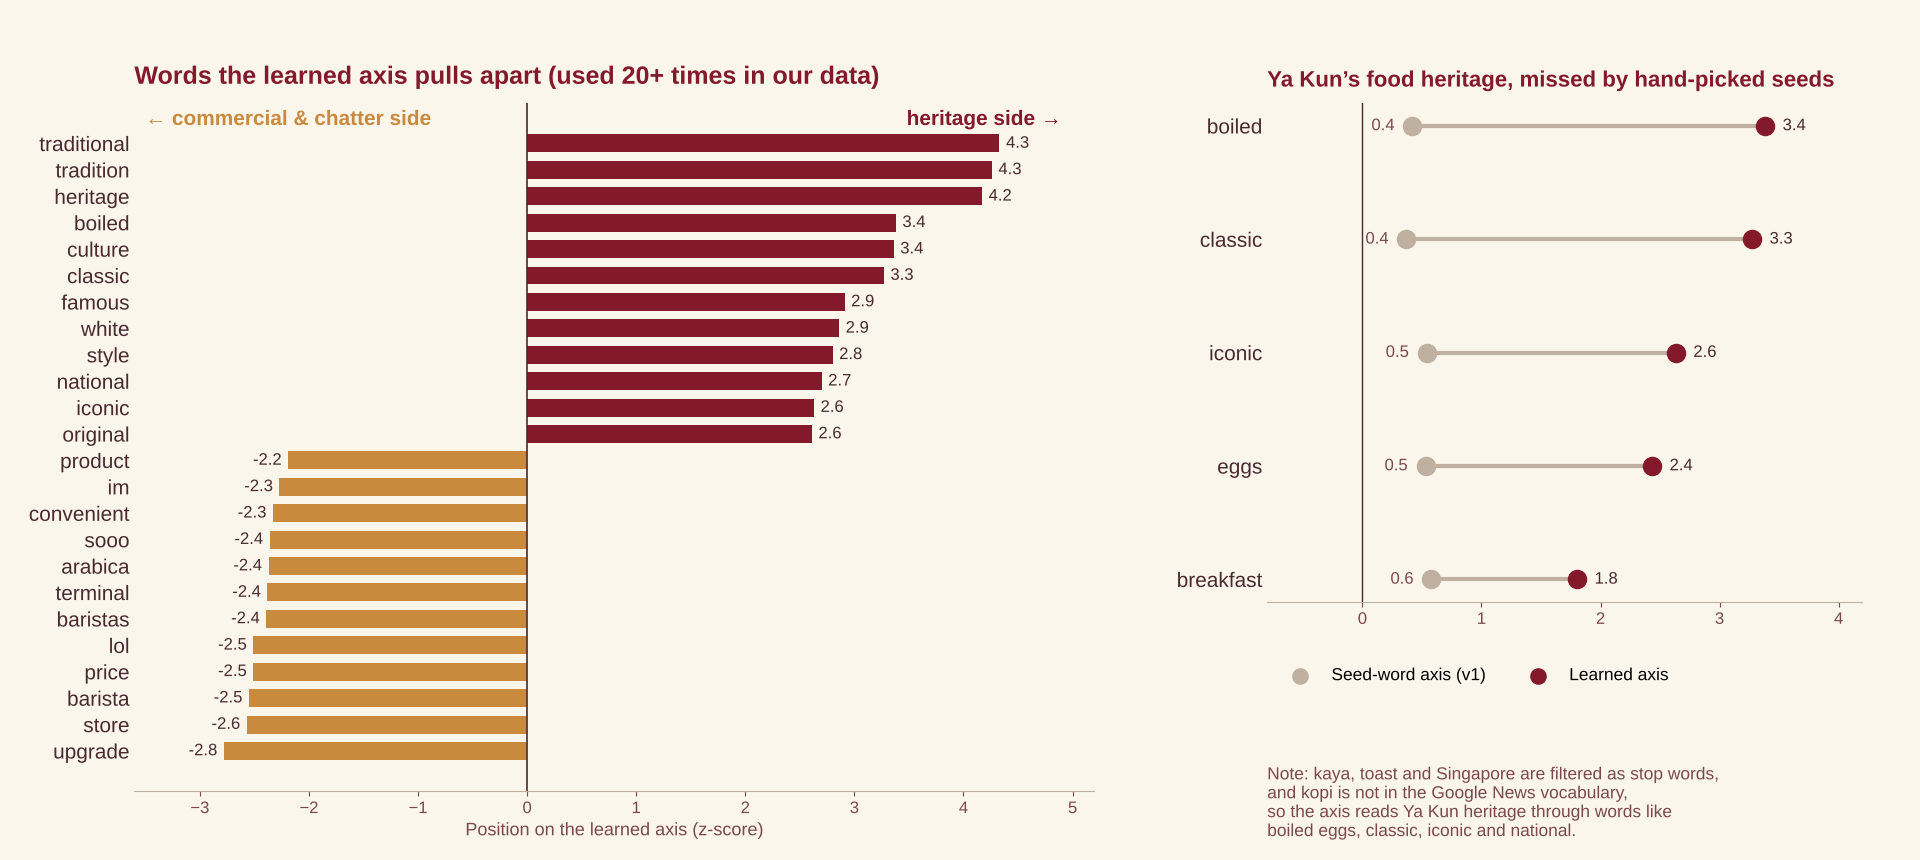

In [25]:
def learn_axis(w2v_path):
    # Original training code (scripts/analysis/rq_1103/axis.py + heritage_axis_extra_1106.py). Needs Google News word2vec.
    from gensim.models import KeyedVectors; from gensim.parsing.preprocessing import STOPWORDS
    from sklearn.model_selection import StratifiedKFold
    wv = KeyedVectors.load(w2v_path); stop = set(STOPWORDS) | {"ya", "kun", "yakun", "kaya", "toast", "singapore", "sg"}
    def emb(t):
        w = [x for x in re.sub(r"[^a-z\s]", " ", re.sub(r"http\S+|@\S+|#", " ", str(t)).lower()).split() if x not in stop and x in wv]
        return np.mean([wv[x] / np.linalg.norm(wv[x]) for x in w], 0) if w else np.zeros(wv.vector_size)
    off = rd(AO / "heritage_二元编码_官方帖641_1103.csv")[["uid", "Hbin"]].rename(columns={"Hbin": "y"})
    dev = pd.concat([off, rd(AO / "RQ2_逐条_1103.csv")[["uid", "anyH"]].rename(columns={"anyH": "y"})])
    dev = dev[~dev.uid.isin(L.uid)].drop_duplicates("uid"); dev["y"] = dev.y.astype(int); dev = dev[dev.uid.map(txt).notna().values]
    Xd = np.vstack(dev.uid.map(txt).apply(emb)); yd = dev.y.values
    lr = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(Xd, yd)
    allX = np.vstack(txt.dropna().apply(emb)); score = pd.Series(lr.predict_proba(allX)[:, 1], index=txt.dropna().index)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xd, yd):         # cross-fitting for training items
        score.loc[dev.uid.values[te]] = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(Xd[tr], yd[tr]).predict_proba(Xd[te])[:, 1]
    return score
HX = learn_axis(W2V_PATH) if W2V_PATH else rd(AO / "heritage轴_交叉拟合分数_1106.csv").set_index("uid").h   # cross-fitted scores
print("cross-fitted scores:", len(HX)); print(rd(AO / "heritage轴_学出的词位置_1106.csv").to_string(index=False))
from IPython.display import Image, display
display(Image(filename=str(AO / "charts_1103" / "heritage轴_学出的词位置图_1106.png"), width=900))   # Figure B2 (drawn with the word2vec vectors, scripts/analysis/rq_1103/heritage_axis_words_1106.py)

### 4.3 Topics (NMF, report §6.2)

In [26]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS; from sklearn.decomposition import NMF
UC = M[(M.content_type != "official_post") & (M.author_type != "brand") & ~M.text_en.astype(str).str.contains(r"\(political, off-topic\)")].copy()
UC["clean"] = (UC.text_en.astype(str).str.lower().str.replace(r"http\S+|@\S+|#", " ", regex=True).str.replace(r"[^a-z\s']", " ", regex=True)
               .str.replace(r"\s+", " ", regex=True).str.strip())
STOP = list(ENGLISH_STOP_WORDS | {"ya", "kun", "yakun", "singapore", "sg", "just", "like", "really", "im", "dont", "don", "lol", "haha", "yes", "oh",
       "got", "know", "video", "fyp", "foryou", "foryoupage", "viral", "tiktok", "shorts", "user", "s", "t", "u", "thank", "thanks", "pls", "need", "want"})
# The report's topic run (5 Nov) was made before the last Xiaohongshu / YouTube translations were merged.
# To reproduce it, the same documents are used (saved in step4_topic_assignments.csv); the current data give 2,249 client documents.
SAVED = rd(AO / "step4_topic_assignments.csv")
print("client documents with current text:", int((UC[UC.yakun_related].clean.str.split().str.len() >= 4).sum()))
TOP = {}
for name, sub, k in [("client", UC[UC.yakun_related], 8), ("industry", UC[UC.industry], 6)]:
    s = sub[sub.uid.isin(SAVED[SAVED.set == name].uid)]                         # posts of 4+ words, as in the report's run
    s = s.set_index("uid").loc[SAVED[SAVED.set == name].uid].reset_index()       # same document order as the saved run
    tv = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=4, max_df=0.5); Xt = tv.fit_transform(s.clean)
    nmf = NMF(n_components=k, random_state=SEED, init="nndsvda", max_iter=500); W = nmf.fit_transform(Xt)
    terms = np.array(tv.get_feature_names_out()); share = pd.Series(W.argmax(1)).value_counts(normalize=True)
    TOP[name] = pd.DataFrame({"share": [round(share.get(i, 0), 2) for i in range(k)],
                              "top terms": [", ".join(terms[c.argsort()[::-1][:6]]) for c in nmf.components_]})
    print(f"\n{name}: {len(s)} posts"); print(TOP[name].sort_values("share", ascending=False).to_string())
check("NMF client documents", int(len(SAVED[SAVED.set == "client"])), 2160, 0)
print(rd(AO / "step4_topics.csv")[["set", "topic", "话题名", "share_of_docs"]].to_string(index=False))   # saved run, with topic names given by us

client documents with current text: 2249

client: 2160 posts
   share                                                                 top terms
5   0.28                                       coffee, tea, kopi, milk, soya, best
0   0.22                       toast, kaya, kaya toast, butter, toast kaya, famous
7   0.10                                        good, make, taste, try, day, looks
3   0.10  yakunkayatoast, breakfast, kayatoast, delicious, sgfoodie, singaporefood
2   0.09                        eggs, boiled, boiled eggs, soft, half, soft boiled
1   0.09                                 food, eat, great, videos, eating, channel
4   0.08                         love, videos, love kaya, egg, love videos, making
6   0.03                              sauce, soy, soy sauce, dark, dark soy, salty

industry: 1492 posts
   share                                                          top terms
5   0.30                           food, good, looks, try, great, delicious
3   0.27          

## 5 Step 1: social media audit (report §3, Tables 3–4)
Window: 25 Apr – 18 Oct 2026 (177 days; the last 7 days before scraping are excluded). Posts per day = posts ÷ 177; engagement per post = total engagement ÷ posts; engagement rate = engagement per post ÷ followers.

In [27]:
PO = rd(CD / "platform_overview_clean.csv"); print(PO[PO.brand == "Ya Kun"][["platform", "followers", "posts_last_3m", "avg_likes_last_3m", "status"]].to_string(index=False))
W0, W1 = pd.Timestamp("2026-04-25"), pd.Timestamp("2026-10-18"); days = (W1 - W0).days + 1
FOL = PO.set_index(["brand", "platform"]).followers.to_dict()
FOL.update({("Ya Kun", "TikTok"): 225, ("Toast Box", "TikTok"): 361, ("Old Chang Kee", "TikTok"): 6064, ("% Arabica", "TikTok"): 83})  # scraped TikTok followers
P["d"] = pd.to_datetime(P.published_date); rows = []
for (b, pf), g in P.groupby(["brand", "platform"]):
    w = g[(g.d >= W0) & (g.d <= W1)]; e = w.engagement.dropna(); f = FOL.get((b, pf))
    rows.append({"brand": b, "platform": pf, "posts": len(w), "posts/day": round(len(w) / days, 2),
                 "eng/post": round(e.mean(), 0) if len(e) else np.nan, "eng rate %": round(e.mean() / f * 100, 2) if len(e) else np.nan, "rate_raw": e.mean() / f if len(e) else np.nan})
T4 = pd.DataFrame(rows).set_index(["brand", "platform"]); print(f"{days} days"); print(T4.to_string())
check("Window length (days)", days, 177, 0)
for b, rep in [("Ya Kun", (0.28, 188, 0.94)), ("Toast Box", (0.29, 78, 0.32)), ("Old Chang Kee", (0.88, 338, 0.97)), ("% Arabica", (0.54, 71, 0.34))]:
    r = T4.loc[(b, "Instagram")]; check(f"{b} IG posts/day", r["posts/day"], rep[0]); check(f"{b} IG eng/post", r["eng/post"], rep[1], 1); check(f"{b} IG eng rate %", r["eng rate %"], rep[2])
yk_tt = P[(P.brand == "Ya Kun") & (P.platform == "TikTok")]; print("Ya Kun TikTok: last post", yk_tt.published_date.max(), "| all-time avg engagement", round(yk_tt.engagement.mean()))
check("Ya Kun likes per follower (SMART baseline, %)", round(132.6 / 20000 * 100, 2), 0.66)

 platform  followers  posts_last_3m  avg_likes_last_3m           status
   TikTok     2700.0            NaN                NaN Inactive(Jan 26)
Instagram    20000.0           29.0              132.6           Active
 Facebook    26000.0           30.0               25.4           Active
177 days
                         posts  posts/day  eng/post  eng rate %  rate_raw
brand         platform                                                   
% Arabica     Instagram     96       0.54      70.0        0.34  0.003356
              TikTok        42       0.24       5.0        6.37  0.063683
Old Chang Kee Instagram    156       0.88     338.0        0.97  0.009654
              TikTok        32       0.18      33.0        0.54  0.005375
Toast Box     Instagram     52       0.29      78.0        0.32  0.003241
              TikTok         7       0.04      25.0        6.96  0.069648
Ya Kun        Instagram     50       0.28     188.0        0.94  0.009400
              TikTok         0       

## 6 Step 2: target audience (report §4)

In [28]:
# 6.1 Who is active: commenters on Ya Kun's posts
yc = CM[CM.brand == "Ya Kun"]
per = yc.groupby("author_anon").post_id.nunique().sort_values(ascending=False)   # number of different posts each person commented on
# one account commented under 36 of Ya Kun's posts with near-identical text; checked by hand and treated as a bot
bot = per[per >= 20].index
ret = per.drop(bot)
print("comments:", len(yc), "| commenters:", per.size, "| returned 3+ times (bot excluded):", int((ret >= 3).sum()))
print("top 5 fans (posts commented on):", ret.head(5).tolist())
check("Commenters on Ya Kun posts", per.size, 365, 0); check("Commenters returning 3+ times", int((ret >= 3).sum()), 14, 0)
check("Comments under Ya Kun posts (all read by hand)", len(yc), 515, 0)
check("Top 5 fans: fewest posts commented on", int(ret.iloc[4]), 6, 0); check("Top 5 fans: most posts commented on", int(ret.iloc[0]), 17, 0)
print("likes per comment from the top 5 fans:", yc[yc.author_anon.isin(ret.index[:5])].likes.describe()[["min", "max"]].to_dict())

comments: 515 | commenters: 365 | returned 3+ times (bot excluded): 14
top 5 fans (posts commented on): [17, 11, 8, 7, 6]
✓ Commenters on Ya Kun posts: notebook 365 | report 365
✓ Commenters returning 3+ times: notebook 14 | report 14
✓ Comments under Ya Kun posts (all read by hand): notebook 515 | report 515
✓ Top 5 fans: fewest posts commented on: notebook 6 | report 6
✓ Top 5 fans: most posts commented on: notebook 17 | report 17
likes per comment from the top 5 fans: {'min': 0.0, 'max': 3.0}


In [29]:
# 6.2 Where conversation happens (last 30 days) and who posts on TikTok
UG = M[(M.content_type != "official_post") & M.author_type.isin(["user", "creator", "ordinary_user"]) & (M.dataset != "M7 Brand24")].copy()
UG["dt"] = pd.to_datetime(UG.published_date, errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
UG = UG[UG.yakun_related | UG.industry]; UG["grp"] = np.where(UG.yakun_related, "client", "industry")
W30 = UG[(UG.dt >= "2026-09-25") & (UG.dt <= "2026-10-24")]
vol = pd.crosstab(W30.dataset, W30.grp, margins=True); print(vol)
yk30 = W30[W30.grp == "client"]; share_ttx = yk30.dataset.isin(["M5 TikTok UGC", "M6 Xiaohongshu notes"]).mean()
check("30-day Ya Kun mentions", len(yk30), 90, 0); check("30-day category mentions", int((W30.grp == "industry").sum()), 97, 0)
check("Share of Ya Kun mentions on TikTok + Xiaohongshu", round(share_ttx, 2), 0.82)
TT = M[(M.dataset == "M5 TikTok UGC") & (M.yakun_related == True) & ~M.author_type.isin(["brand", "brand_or_franchise"]) & (M.views > 0)].copy()
TT["h"] = TT.uid.map(HX); TT = TT.dropna(subset=["h"])
print("TikTok videos:", len(TT)); print((TT.lang.value_counts(normalize=True).head(5) * 100).round(0))
check("TikTok Ya Kun videos analysed", len(TT), 412, 0); check("TikTok videos in English (%)", round(TT.lang.eq("en").mean() * 100), 56, 0.5)
check("TikTok videos from creators <10k followers (%)", round((TT.author_fans < 10000).mean() * 100), 72, 0.5)

grp                        client  industry  All
dataset                                         
M11 YouTube comments            4        57   61
M11 YouTube videos              7         2    9
M4 official-post comments       5         0    5
M5 TikTok UGC                  47        26   73
M6 Xiaohongshu notes           27        12   39
All                            90        97  187
✓ 30-day Ya Kun mentions: notebook 90 | report 90
✓ 30-day category mentions: notebook 97 | report 97
✓ Share of Ya Kun mentions on TikTok + Xiaohongshu: notebook 0.82 | report 0.82
TikTok videos: 412
lang
en    56.0
th    17.0
id     8.0
ha     5.0
ja     4.0
Name: proportion, dtype: float64
✓ TikTok Ya Kun videos analysed: notebook 412 | report 412
✓ TikTok videos in English (%): notebook 56 | report 56
✓ TikTok videos from creators <10k followers (%): notebook 72 | report 72


In [30]:
# 6.3 Potential influencers (creators already featuring Ya Kun; brand, franchise and media accounts excluded)
INF = rd(AO / "Step2_潜在影响者候选_1103.csv")
print(INF[INF.handle.isin(["Zermatt Neo", "chloeuchida", "cabalenfoodie", "吃貨豪豪HowHowEat", "foodhunterph", "madeinsg_", "avicadoes", "Ghib Ojisan"])]
      [["handle", "platform", "fans", "avg_views", "epv"]].to_string(index=False))

       handle platform    fans  avg_views     epv
  Zermatt Neo  YouTube 4580000   198519.0 0.01660
吃貨豪豪HowHowEat  YouTube  875000   347143.0 0.01340
  chloeuchida   TikTok  632500    47700.0 0.00520
  Ghib Ojisan  YouTube  365000   159472.0 0.01540
cabalenfoodie   TikTok  167400    80300.0 0.02540
 foodhunterph   TikTok   49100   432300.0 0.05110
    avicadoes   TikTok   24900    28171.5 0.03985
    madeinsg_   TikTok   14700   322800.0 0.06100


## 7 Step 3 and RQ1: what works on Ya Kun's channels (report §5)
243 Ya Kun Instagram posts (Jul 2024 – Oct 2026). **Relative engagement** = post engagement ÷ median engagement of Ya Kun's posts in the same year. Heritage = validated yes/no code; novelty = collaboration, new product or merchandise (Y2–Y4, the three tactics that passed reliability).

In [31]:
R1 = rd(AO / "RQ1_逐条_v2_1103.csv", dtype={"post_id": str})
R1["year"] = pd.to_datetime(R1.published_date).dt.year
R1["rel"] = R1.engagement / R1.groupby("year").engagement.transform("median")
R1["N"] = R1.C_youth.fillna("").str.split(";").apply(lambda c: any(x.strip() in ("Y2", "Y3", "Y4") for x in c)).astype(int)
R1["type"] = np.select([(R1.Hbin == 1) & (R1.N == 0), (R1.Hbin == 1) & (R1.N == 1), (R1.Hbin == 0) & (R1.N == 1)], ["Heritage only", "Heritage + novelty", "Novelty only"], "Neither")
check("RQ1 posts", len(R1), 243, 0)
med = R1.groupby("Hbin").rel.median(); p = mwu_p(R1[R1.Hbin == 1].rel, R1[R1.Hbin == 0].rel)
check("Median rel. engagement, heritage", round(med[1], 2), 1.15); check("Median rel. engagement, non-heritage", round(med[0], 2), 0.89)
check("Mann-Whitney p, heritage vs not", round(p, 3), 0.006, 0.0011)
T6 = R1.groupby("type").rel.agg(["count", "median", "mean"]).round(2).reindex(["Heritage only", "Heritage + novelty", "Neither", "Novelty only"]); print(T6)
for t, (n, md_, mn) in {"Heritage only": (27, 1.33, 2.95), "Heritage + novelty": (51, 1.06, 3.57), "Neither": (102, 0.93, 1.68), "Novelty only": (63, 0.89, 1.47)}.items():
    check(f"{t}: n", T6.loc[t, "count"], n, 0); check(f"{t}: median", T6.loc[t, "median"], md_); check(f"{t}: mean", T6.loc[t, "mean"], mn)
check("Heritage only vs novelty only, p", round(mwu_p(R1[R1.type == "Heritage only"].rel, R1[R1.type == "Novelty only"].rel), 2), 0.02)
print("Kruskal-Wallis, four types: p =", round(kruskal(*[g.rel for _, g in R1.groupby("type")]).pvalue, 3))

✓ RQ1 posts: notebook 243 | report 243
✓ Median rel. engagement, heritage: notebook 1.15 | report 1.15
✓ Median rel. engagement, non-heritage: notebook 0.89 | report 0.89
✓ Mann-Whitney p, heritage vs not: notebook 0.006 | report 0.006
                    count  median  mean
type                                   
Heritage only          27    1.33  2.95
Heritage + novelty     51    1.06  3.57
Neither               102    0.93  1.68
Novelty only           63    0.89  1.47
✓ Heritage only: n: notebook 27 | report 27
✓ Heritage only: median: notebook 1.33 | report 1.33
✓ Heritage only: mean: notebook 2.95 | report 2.95
✓ Heritage + novelty: n: notebook 51 | report 51
✓ Heritage + novelty: median: notebook 1.06 | report 1.06
✓ Heritage + novelty: mean: notebook 3.57 | report 3.57
✓ Neither: n: notebook 102 | report 102
✓ Neither: median: notebook 0.93 | report 0.93
✓ Neither: mean: notebook 1.68 | report 1.68
✓ Novelty only: n: notebook 63 | report 63
✓ Novelty only: median: notebook 0.89 

In [32]:
# Robustness: raw engagement, without the top 5 posts, and within each year
print("raw engagement p =", round(mwu_p(R1[R1.Hbin == 1].engagement, R1[R1.Hbin == 0].engagement), 4))
r5 = R1.drop(R1.engagement.nlargest(5).index); print("without top 5: medians", r5.groupby("Hbin").rel.median().round(2).to_dict())
print(R1.groupby(["year", "Hbin"]).rel.median().unstack().round(2))

raw engagement p = 0.0028
without top 5: medians {0: 0.89, 1: 1.11}
Hbin     0     1
year            
2024  0.93  1.28
2025  0.83  1.07
2026  0.96  1.40


In [33]:
# Regression: log relative engagement on heritage + controls (OLS, HC3 robust SE)
off = P.drop_duplicates("post_id").set_index("post_id")
R1["format"] = R1.post_id.map(off.format); R1["coauth"] = R1.post_id.map(off.is_coauthor_post).fillna(False).astype(int)
R1["fest"] = pd.to_datetime(R1.published_date).dt.month.isin([1, 2, 8, 9, 12]).astype(int)        # CNY, National Day, Mid-Autumn, Christmas months
R1["bond"] = R1.uid.map(rd(AO / "人际联结_官方帖256_1103.csv").set_index("uid").bond).fillna(0).astype(int)   # relational theme (control)
reg1 = smf.ols('np.log(rel) ~ Hbin + N + coauth + C(format, Treatment("carousel")) + bond + fest + C(year)', R1).fit(cov_type="HC3")
print(pd.DataFrame({"times": np.exp(reg1.params).round(2), "p": reg1.pvalues.round(3)}))
check("Regression R²", round(reg1.rsquared, 2), 0.26); check("Heritage effect (×)", round(np.exp(reg1.params["Hbin"]), 2), 1.56)
check("Novelty effect (×)", round(np.exp(reg1.params["N"]), 2), 0.88); check("Novelty p", round(reg1.pvalues["N"], 2), 0.22)
check("Single image vs carousel (×)", round(np.exp(reg1.params['C(format, Treatment("carousel"))[T.image]']), 2), 0.60)
check("Video vs carousel (×)", round(np.exp(reg1.params['C(format, Treatment("carousel"))[T.reel_video]']), 2), 0.51)

                                                times      p
Intercept                                        1.71  0.001
C(format, Treatment("carousel"))[T.image]        0.60  0.001
C(format, Treatment("carousel"))[T.reel_video]   0.51  0.000
C(year)[T.2025]                                  1.03  0.833
C(year)[T.2026]                                  1.17  0.250
Hbin                                             1.56  0.001
N                                                0.88  0.216
coauth                                           4.36  0.002
bond                                             0.71  0.010
fest                                             0.81  0.044
✓ Regression R²: notebook 0.26 | report 0.26
✓ Heritage effect (×): notebook 1.56 | report 1.56
✓ Novelty effect (×): notebook 0.88 | report 0.88
✓ Novelty p: notebook 0.22 | report 0.22
✓ Single image vs carousel (×): notebook 0.6 | report 0.6
✓ Video vs carousel (×): notebook 0.51 | report 0.51


In [34]:
# Format (Figure 2)
fm = R1.groupby("format").rel.median().round(2); print(fm)
check("Carousel median", fm["carousel"], 1.62); check("Image median", fm["image"], 0.90); check("Video median", fm["reel_video"], 0.88)
vid = R1[R1.format == "reel_video"].groupby("Hbin").rel.median().round(2)
check("Video with heritage", vid[1], 1.40); check("Video without heritage", vid[0], 0.80)

format
carousel      1.62
image         0.90
reel_video    0.88
Name: rel, dtype: float64
✓ Carousel median: notebook 1.62 | report 1.62
✓ Image median: notebook 0.9 | report 0.9
✓ Video median: notebook 0.88 | report 0.88
✓ Video with heritage: notebook 1.4 | report 1.4
✓ Video without heritage: notebook 0.8 | report 0.8


In [35]:
# Step 3 top posts: Ya Kun top 10 IG + top 10 TikTok, coded by two members (final codes after tie-break)
S35 = rd(AO / "S3S5_最终编码_含第三方裁定_1103.csv")
S3 = S35[S35.set == "S3"]; ig10, tt10 = S3[S3.platform == "Instagram"], S3[S3.platform == "TikTok"]
T7 = S3.groupby(["P2", "platform"]).engagement.agg(["count", "mean"]).round(0).unstack(); print(T7)
check("Top-10 IG posts with heritage", int((ig10[["H1", "H2", "H3", "H4", "H5"]].sum(1) > 0).sum()), 9, 0)
check("Top-10 IG carousel avg engagement", round(ig10[ig10.format == "carousel"].engagement.mean()), 3037, 1)
check("Top-10 IG single image avg engagement", round(ig10[ig10.format == "image"].engagement.mean()), 1429, 1)
check("Top-10 IG collaboration avg engagement", round(ig10[ig10.P2 == "T-COLLAB"].engagement.mean()), 3058, 1)
check("Top-10 TikTok avg engagement", round(tt10.engagement.mean()), 53, 1)
print("disagreements resolved by choosing one coder's answer:", int((S35.filter(like="_src") == "Claude 第三方裁定").sum().sum()))

                count             mean       
platform    Instagram TikTok Instagram TikTok
P2                                           
T-COLLAB          3.0    NaN    3058.0    NaN
T-COMMUNITY       2.0    1.0    2549.0   24.0
T-FEST            NaN    2.0       NaN  210.0
T-HERITAGE        1.0    1.0    1263.0    8.0
T-NEW             1.0    2.0     943.0   17.0
T-OTHER           1.0    1.0    1107.0    9.0
T-PROMO           1.0    1.0     734.0   11.0
T-STORE           1.0    2.0     628.0   13.0
✓ Top-10 IG posts with heritage: notebook 9 | report 9
✓ Top-10 IG carousel avg engagement: notebook 3037 | report 3037
✓ Top-10 IG single image avg engagement: notebook 1429 | report 1429
✓ Top-10 IG collaboration avg engagement: notebook 3058 | report 3058
✓ Top-10 TikTok avg engagement: notebook 53 | report 53
disagreements resolved by choosing one coder's answer: 139


## 8 Step 4 and RQ2: social listening and users (report §6)
RQ2 base: 2,470 LLM-coded user items → relevant (A1 = R1/R2) → minus suspected bots, commercial, promotion, travel and news sources = **1,575**.

In [36]:
# 8.1 Sentiment of the past 30 days, Ya Kun vs category (Twitter-RoBERTa; LLM coding as cross-check)
# Ya Kun set = the 30-day Ya Kun mentions that are also in the RQ2 base (relevant, ordinary users): 80 of 90.
# Category set = 97 category mentions of the same 30 days, LLM-coded with the same codebook.
IND = rd(AO / "Step4_行业情感_AI编码_1103.csv")
yk30s = yk30[yk30.uid.isin(R2.index)].uid
sets = {"Ya Kun, 30 days": yk30s, "Category, 30 days": IND[IND.in30].uid}
for name, uids in sets.items():
    s = uids.map(ROB).value_counts(normalize=True).mul(100).round(0); print(name, len(uids), s.to_dict())
check("Ya Kun 30-day mentions in RQ2 base", len(yk30s), 80, 0)
check("RoBERTa positive, Ya Kun 30 days (%)", round(yk30s.map(ROB).eq("P").mean() * 100), 60, 0.5)
check("RoBERTa positive, category 30 days (%)", round(IND[IND.in30].uid.map(ROB).eq("P").mean() * 100), 55, 0.5)
check("LLM positive, Ya Kun 30 days (%)", round(yk30s.map(R2.F_sentiment).eq("F1").mean() * 100), 44, 0.5)
check("LLM positive, category 30 days (%)", round(IND[IND.in30].F_ai.eq("P").mean() * 100), 43, 0.5)
print("RoBERTa robustness table saved during analysis:"); print(rd(AO / "Step4_情感_RoBERTa稳健性_1103.csv").to_string(index=False))

Ya Kun, 30 days 80 {'P': 60.0, 'U': 35.0, 'N': 5.0}
Category, 30 days 97 {'P': 55.0, 'U': 35.0, 'N': 10.0}
✓ Ya Kun 30-day mentions in RQ2 base: notebook 80 | report 80
✓ RoBERTa positive, Ya Kun 30 days (%): notebook 60 | report 60
✓ RoBERTa positive, category 30 days (%): notebook 55 | report 55
✓ LLM positive, Ya Kun 30 days (%): notebook 44 | report 44
✓ LLM positive, category 30 days (%): notebook 43 | report 43
RoBERTa robustness table saved during analysis:
          组    n  正面%  中性%  负面%
Ya Kun，30 天   80 60.0 35.0  5.0
    行业，30 天   97 54.6 35.1 10.3
  Ya Kun，全部 1575 52.8 37.1 10.1
  行业，随机 200  200 60.5 31.0  8.5


In [37]:
# 8.2 RQ2 base and the weight of heritage
UAI = rd(AO / "ai_precode_user_content.csv")
EXCL = ["suspected_bot", "commercial_listing", "promo_site", "travel_site", "news_media"]
base = UAI[UAI.A1_relevance.isin(["R1", "R2"]) & ~UAI.author_type.isin(EXCL)]
check("LLM-coded user items", len(UAI), 2470, 0); check("RQ2 base", len(base), 1575, 0)
R2 = R2.reset_index()
check("Heritage share of user content (%)", round(R2.anyH.mean() * 100), 33, 0.5); check("Heritage items", int(R2.anyH.sum()), 516, 0)
pos = R2.groupby("anyH").F_sentiment.apply(lambda s: s.eq("F1").mean() * 100).round(0)
p_chi = chi2_contingency(pd.crosstab(R2.anyH, R2.F_sentiment))[1]
check("Positive with heritage (LLM, %)", pos[True], 61, 0.5); check("Positive without heritage (LLM, %)", pos[False], 39, 0.5); print("chi-square p =", p_chi)
rb = R2.uid.map(ROB); posr = rb.eq("P").groupby(R2.anyH).mean().mul(100).round(0)
check("Positive with heritage (RoBERTa, %)", posr[True], 64, 0.5); check("Positive without heritage (RoBERTa, %)", posr[False], 47, 0.5)
check("Items calling Ya Kun outdated", int((R2.E_dated == "D1").sum()), 7, 0)

✓ LLM-coded user items: notebook 2470 | report 2470
✓ RQ2 base: notebook 1575 | report 1575
✓ Heritage share of user content (%): notebook 33 | report 33
✓ Heritage items: notebook 516 | report 516
✓ Positive with heritage (LLM, %): notebook 61.0 | report 61
✓ Positive without heritage (LLM, %): notebook 39.0 | report 39
chi-square p = 2.1448106199397823e-18
✓ Positive with heritage (RoBERTa, %): notebook 64.0 | report 64
✓ Positive without heritage (RoBERTa, %): notebook 47.0 | report 47
✓ Items calling Ya Kun outdated: notebook 7 | report 7


In [38]:
# 8.3 Meanings of heritage: users vs brand (share of heritage items; one item can have several meanings)
Hc = ["H1", "H2", "H3", "H4", "H5"]; names = dict(zip(Hc, ["founding story", "traditional craft", "personal memory", "Singapore identity", "kopitiam culture"]))
off_ai = rd(AO / "ai_precode_yakun_official.csv"); bh = off_ai.B_heritage.fillna("H0").astype(str); bh = bh[~bh.str.fullmatch("H0")]
MEAN = pd.DataFrame({"users %": (R2[R2.anyH][Hc].mean() * 100).round(1).values, "brand %": [round(bh.str.contains(h).mean() * 100, 1) for h in Hc]},
                    index=[names[h] for h in Hc]); print(MEAN, "\nusers n =", int(R2.anyH.sum()), "| brand n =", len(bh))
for h, u_, b_ in [("H5", 50.0, 40.8), ("H4", 39.9, 38.0), ("H1", 13.8, 12.0)]:
    check(f"{names[h]}: users %", MEAN.loc[names[h], "users %"], u_, 0.05); check(f"{names[h]}: brand %", MEAN.loc[names[h], "brand %"], b_, 0.05)

                    users %  brand %
founding story         13.8     12.0
traditional craft       6.0     22.5
personal memory        10.7     14.8
Singapore identity     39.9     38.0
kopitiam culture       50.0     40.8 
users n = 516 | brand n = 142
✓ kopitiam culture: users %: notebook 50.0 | report 50.0
✓ kopitiam culture: brand %: notebook 40.8 | report 40.8
✓ Singapore identity: users %: notebook 39.9 | report 39.9
✓ Singapore identity: brand %: notebook 38.0 | report 38.0
✓ founding story: users %: notebook 13.8 | report 13.8
✓ founding story: brand %: notebook 12.0 | report 12.0


In [39]:
# 8.5 Reddit (quotes only, not in the 1,575 base). Political / social-news threads and unrelated daily-chat comments removed; no usernames kept.
import html as _html
RD = R.copy(); RD["text"] = RD.body.fillna("").astype(str).map(_html.unescape)
KEEP = {"t3_17ohfd9": "2023 Ya Kun wedding at Far East Square", "t3_1m21k2y": "2025 Fullerton hotel Ya Kun high tea S$60++",
        "t3_1s5l7dy": "2026 Ya Kun set in Tokyo", "t3_hbruvn": "2020 Ya Kun opens in Shinjuku", "t3_8u4uer": "2018 tourist itinerary advice",
        "t3_1uhf8sb": "2026 daily thread (Ya Kun mentions only)"}
RQ = RD[(RD.dataType == "comment") & RD.postId.isin(KEEP)].copy(); RQ["thread"] = RQ.postId.map(KEEP)
mention = RQ.text.str.contains(r"ya ?kun|kaya|kopi|toast|teh", case=False)
RQ = RQ[~RQ.postId.isin(["t3_1uhf8sb", "t3_8u4uer"]) | mention].sort_values(["thread", "upVotes"], ascending=[True, False])
print(len(R), "Reddit rows ->", len(RQ), "relevant comments"); print(RQ.thread.value_counts().to_string())
print(RQ.groupby("thread").head(1)[["thread", "upVotes", "text"]].assign(text=lambda d: d.text.str[:150]).to_string(index=False))

275 Reddit rows -> 82 relevant comments
thread
2020 Ya Kun opens in Shinjuku                  20
2023 Ya Kun wedding at Far East Square         20
2025 Fullerton hotel Ya Kun high tea S$60++    20
2026 Ya Kun set in Tokyo                       20
2018 tourist itinerary advice                   1
2026 daily thread (Ya Kun mentions only)        1
                                     thread  upVotes                                                                                                                                                    text
              2018 tourist itinerary advice      NaN  You can go to any Ya Kun outlet, you don't have to restrict yourself to the one at Far East Sq. A half day hiking trip at Macritchie or Bukit Timah Hi
              2020 Ya Kun opens in Shinjuku    141.0 Don't discount the ambience and environment when eating.\nSomething about sipping kopi and dipping my Kaya toast in egg in the middle of shinjuku would
     2023 Ya Kun wedding at Far East S

In [40]:
# 8.4 Where heritage appears (Figure 5): learned axis and LLM code by source
R2["h"] = R2.uid.map(HX)
SRC = R2.groupby("dataset").agg(n=("uid", "size"), axis_median=("h", "median"), llm_pct=("anyH", "mean")).round(3)
SRC["llm_pct"] = (SRC.llm_pct * 100).round(0); print(SRC.sort_values("axis_median", ascending=False))
print("Kruskal-Wallis (axis) p =", kruskal(*[g.h.dropna() for _, g in R2.groupby("dataset")]).pvalue)
check("Axis median, comments on Ya Kun posts", round(SRC.loc["M4 official-post comments", "axis_median"], 2), 0.36, 0.011)
check("LLM heritage %, comments on Ya Kun posts", SRC.loc["M4 official-post comments", "llm_pct"], 13, 0.5)
check("Axis median, Xiaohongshu", round(SRC.loc["M6 Xiaohongshu notes", "axis_median"], 2), 0.55, 0.011)

                             n  axis_median  llm_pct
dataset                                             
M6 Xiaohongshu notes        83        0.548     39.0
M11 YouTube videos         115        0.532     59.0
M7 Brand24                  36        0.507     44.0
M11 YouTube comments       504        0.492     38.0
M5 TikTok UGC              396        0.492     39.0
M4 official-post comments  441        0.365     13.0
Kruskal-Wallis (axis) p = 5.075809808349339e-53
✓ Axis median, comments on Ya Kun posts: notebook 0.36 | report 0.36
✓ LLM heritage %, comments on Ya Kun posts: notebook 13.0 | report 13
✓ Axis median, Xiaohongshu: notebook 0.55 | report 0.55


## 9 Step 5 and RQ3: competitors (report §7)
Last six months of official posts (25 Apr – 24 Oct 2026; 435 posts, IG + TikTok). The window is the same for all brands because the Instagram scraper returns at most 300 posts per account, which would truncate Old Chang Kee over a longer window.

In [41]:
HB = rd(AO / "heritage_二元编码_官方帖641_1103.csv"); W6 = HB[HB.win6.astype(str) == "True"]
sh = W6.groupby("brand").Hbin.agg(["sum", "size", "mean"]); sh["mean"] = (sh["mean"] * 100).round(1); print(sh)
check("Posts in 6-month window", len(W6), 435, 0)
for b, rep in [("Toast Box", 39.0), ("Ya Kun", 26.0), ("Old Chang Kee", 21.3), ("% Arabica", 2.2)]: check(f"{b} heritage share %", sh.loc[b, "mean"], rep, 0.05)
for b, g in W6[W6.platform == "Instagram"].groupby("brand"):
    g = g.dropna(subset=["engagement"]); a, c_ = g[g.Hbin == 1].engagement, g[g.Hbin == 0].engagement
    print(f"{b}: heritage median {a.median()} (n={len(a)}) vs other {c_.median()} (n={len(c_)}), p = {mwu_p(a, c_):.4f}")
yk = W6[(W6.brand == "Ya Kun") & (W6.platform == "Instagram")]
check("Ya Kun IG heritage vs other, p", round(mwu_p(yk[yk.Hbin == 1].engagement, yk[yk.Hbin == 0].engagement), 3), 0.050, 0.0011)

               sum  size  mean
brand                         
% Arabica        3   138   2.2
Old Chang Kee   40   188  21.3
Toast Box       23    59  39.0
Ya Kun          13    50  26.0
✓ Posts in 6-month window: notebook 435 | report 435
✓ Toast Box heritage share %: notebook 39.0 | report 39.0
✓ Ya Kun heritage share %: notebook 26.0 | report 26.0
✓ Old Chang Kee heritage share %: notebook 21.3 | report 21.3
✓ % Arabica heritage share %: notebook 2.2 | report 2.2
% Arabica: heritage median 74.0 (n=3) vs other 54.0 (n=93), p = 0.3540
Old Chang Kee: heritage median 120.5 (n=30) vs other 121.0 (n=109), p = 0.8317
Toast Box: heritage median 76.0 (n=21) vs other 57.0 (n=31), p = 0.7370
Ya Kun: heritage median 105.0 (n=13) vs other 72.0 (n=37), p = 0.0503
✓ Ya Kun IG heritage vs other, p: notebook 0.05 | report 0.05


In [42]:
# Competitors' top 5 posts per brand and platform (30 posts)
S5 = S35[S35.set == "S5"].copy()
S5["heritage"] = S5[["H1", "H2", "H3", "H4", "H5"]].sum(1) > 0; S5["any_new"] = S5[[f"Y{i}" for i in range(1, 7)]].sum(1) > 0
T8 = S5.groupby(["brand", "platform"]).agg(avg_eng=("engagement", "mean"), heritage=("heritage", "sum"), any_new_tactic=("any_new", "sum")).round(0); print(T8)
print(S5.groupby(["P2", "platform"]).engagement.agg(["count", "mean"]).round(0).unstack())
check("OCK IG top-5 avg engagement", T8.loc[("Old Chang Kee", "Instagram"), "avg_eng"], 3541, 1)
check("Competitor collaboration avg engagement (IG)", round(S5[(S5.P2 == "T-COLLAB") & (S5.platform == "Instagram")].engagement.mean()), 2988, 1)

                         avg_eng  heritage  any_new_tactic
brand         platform                                    
% Arabica     Instagram    381.0         1               3
              TikTok        14.0         0               0
Old Chang Kee Instagram   3541.0         2               5
              TikTok       104.0         0               5
Toast Box     Instagram    240.0         5               3
              TikTok        33.0         2               4
                count             mean       
platform    Instagram TikTok Instagram TikTok
P2                                           
T-COLLAB          5.0    NaN    2988.0    NaN
T-COMMUNITY       1.0    8.0     253.0   64.0
T-FEST            NaN    1.0       NaN   35.0
T-HERITAGE        2.0    NaN     292.0    NaN
T-NEW             2.0    2.0    1585.0   40.0
T-PROMO           1.0    2.0     256.0   51.0
T-STORE           4.0    2.0     401.0   13.0
✓ OCK IG top-5 avg engagement: notebook 3541.0 | report 3541
✓ Compe

## 10 RQ4: Ya Kun on youth-skewed platforms (report §8)
### 10.1 Xiaohongshu (descriptive)
182 Ya Kun-related notes (title + first ~60 characters). Keyword tagging did not reach usable agreement (κ 0.30–0.43), so cues are described, not coded per note. IP location and identity cues are not used.

In [43]:
Y = xm[xm.relevance.isin(["yakun_text", "yakun_inferred"])].copy(); Y["t"] = (Y.title.fillna("") + " " + Y.desc.fillna("")).str.lower()
CUES = {"check-in / must-try / guide": r"打卡|必吃|必去|必喝|国民早餐|國民早餐|攻略|旅游|旅行|游客|遊客|行程|citywalk|第一次来|来新加坡|來新加坡|樟宜|机场",
        "soya coffee": r"豆浆|豆漿|soya|soy",
        "too sweet / less sugar": r"太甜|好甜|很甜|偏甜|有点甜|有點甜|甜腻|甜膩|齁|少甜|无糖|無糖|少糖|kosong|siew dai|siu dai",
        "ordering guide / how to eat": r"怎么点|怎麼點|点单|點單|攻略|不踩雷|怎么吃|怎麼吃|教你|指南"}
for k, rx in CUES.items(): Y[k] = Y.t.str.contains(rx)
XS = pd.DataFrame({"share %": [round(Y[k].mean() * 100) for k in CUES], "median eng (with)": [Y[Y[k]].engagement.median() for k in CUES],
                   "median eng (without)": [Y[~Y[k]].engagement.median() for k in CUES]}, index=list(CUES)); print(XS)
check("Xiaohongshu Ya Kun notes", len(Y), 182, 0)
check("Ordering-guide notes, median engagement", XS.loc["ordering guide / how to eat", "median eng (with)"], 227, 0.5)
check("Other notes, median engagement", XS.loc["ordering guide / how to eat", "median eng (without)"], 42, 0.5)

                             share %  median eng (with)  median eng (without)
check-in / must-try / guide       47               80.0                  28.0
soya coffee                       33               31.0                  55.0
too sweet / less sugar            13               49.0                  46.0
ordering guide / how to eat        7              227.0                  42.0
✓ Xiaohongshu Ya Kun notes: notebook 182 | report 182
✓ Ordering-guide notes, median engagement: notebook 227.0 | report 227
✓ Other notes, median engagement: notebook 42.0 | report 42


### 10.2 TikTok: heritage score, reach and response
412 Ya Kun-related user videos scored on the learned heritage axis. Reach = views; response = engagement per view. Because views also depend on the creator and the video, the regression controls for creator followers, duration, video age, format and language (added after the presentation, where the lack of controls was raised).

In [44]:
TT["epv"] = TT.engagement / TT.views; TT["tert"] = pd.qcut(TT.h, 3, labels=["low", "mid", "high"])
TER = TT.groupby("tert").agg(views_median=("views", "median"), epv_median=("epv", "median")).round(4); print(TER)
rv, re_ = spearmanr(TT.h, TT.views), spearmanr(TT.h, TT.epv)
for t, v in zip(["low", "mid", "high"], [5668, 4685, 2616]): check(f"Median views, {t} heritage", TER.loc[t, "views_median"], v, 0.5)
check("Spearman ρ heritage vs views", round(rv.correlation, 2), -0.11); check("p (views)", round(rv.pvalue, 2), 0.03)
check("Spearman ρ heritage vs engagement per view", round(re_.correlation, 2), 0.05); check("p (eng per view)", round(re_.pvalue, 2), 0.28)

      views_median  epv_median
tert                          
low         5668.0      0.0264
mid         4685.0      0.0229
high        2616.0      0.0291


✓ Median views, low heritage: notebook 5668.0 | report 5668


✓ Median views, mid heritage: notebook 4685.0 | report 4685
✓ Median views, high heritage: notebook 2616.0 | report 2616
✓ Spearman ρ heritage vs views: notebook -0.11 | report -0.11
✓ p (views): notebook 0.03 | report 0.03
✓ Spearman ρ heritage vs engagement per view: notebook 0.05 | report 0.05
✓ p (eng per view): notebook 0.28 | report 0.28


In [45]:
TU = U.set_index(U.video_id.astype(str))
TT["vid"] = TT.uid.str[3:]
TT["duration"] = TT.vid.map(TU.duration_sec); TT["fmt"] = TT.vid.map(TU.format); TT["author"] = TT.vid.map(TU.author_anon); TT["tourist"] = TT.vid.map(TU.tourist_cue)
TT["age_days"] = (pd.Timestamp("2026-10-25") - pd.to_datetime(TT.published_date, errors="coerce")).dt.days.clip(lower=0)
TT["lviews"], TT["lfans"], TT["ldur"], TT["lage"] = np.log1p(TT.views), np.log1p(TT.author_fans), np.log1p(TT.duration), np.log1p(TT.age_days)
TT["slide"] = TT.fmt.astype(str).str.contains("slide").astype(int); TT["en"] = TT.lang.astype(str).str.startswith("en").astype(int)
TT["hz"] = (TT.h - TT.h.mean()) / TT.h.std()                                       # standardised heritage score
f = "lviews ~ hz + lfans + ldur + lage + slide + en"
reg4 = smf.ols(f, TT).fit(cov_type="HC3"); print(reg4.summary().tables[1])
check("Heritage coefficient (log views, per SD)", round(reg4.params["hz"], 3), -0.175, 0.0006); check("p", round(reg4.pvalues["hz"], 3), 0.029, 0.0011)
check("≈ % fewer views per SD", round((1 - np.exp(reg4.params["hz"])) * 100), 16, 0.5); check("R²", round(reg4.rsquared, 3), 0.40)
pc = smf.ols(f, TT).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(TT.author)[0]}).pvalues["hz"]
check("p, SE clustered by creator", round(pc, 3), 0.029, 0.0011); check("Creators", TT.author.nunique(), 370, 0)
check("p, + tourist cue", round(smf.ols(f + " + C(tourist)", TT).fit(cov_type="HC3").pvalues["hz"], 3), 0.049, 0.0011)
check("p, heritage on engagement per view (controls)", round(smf.ols("epv ~ hz + lfans + ldur + lage + slide + en", TT).fit(cov_type="HC3").pvalues["hz"], 2), 0.21)
print("max |ρ| of heritage with followers, duration, age:", round(max(abs(spearmanr(TT.h, TT[c], nan_policy='omit').correlation) for c in ["author_fans", "duration", "age_days"]), 2))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.4723      0.506      4.886      0.000       1.481       3.464
hz            -0.1748      0.080     -2.181      0.029      -0.332      -0.018
lfans          0.3527      0.031     11.267      0.000       0.291       0.414
ldur           0.2076      0.115      1.806      0.071      -0.018       0.433
lage           0.4009      0.058      6.904      0.000       0.287       0.515
slide          1.2442      0.483      2.579      0.010       0.299       2.190
en             0.4538      0.159      2.845      0.004       0.141       0.766
✓ Heritage coefficient (log views, per SD): notebook -0.175 | report -0.175
✓ p: notebook 0.029 | report 0.029
✓ ≈ % fewer views per SD: notebook 16 | report 16
✓ R²: notebook 0.395 | report 0.4


✓ p, SE clustered by creator: notebook 0.028 | report 0.029
✓ Creators: notebook 370 | report 370
✓ p, + tourist cue: notebook 0.049 | report 0.049


✓ p, heritage on engagement per view (controls): notebook 0.21 | report 0.21
max |ρ| of heritage with followers, duration, age: 0.06


### 10.3 Dropped: tourist vs local comparison
Tourist-oriented posts scored higher on the heritage axis, but they came mostly from YouTube videos while local posts included comments under Ya Kun's posts, so platform and orientation cannot be separated. The comparison is shown for transparency and not reported as a finding.

In [46]:
TL = rd(AO / "heritage轴_RQ4游客vs本地_1106.csv"); TL["dataset"] = TL.uid.map(Ms.dataset); print(pd.crosstab(TL.dataset, TL.iloc[:, 1]))

组员1 G               T1  T2
dataset                   
M11 YouTube videos   9   1
M5 TikTok UGC        7   2


## 11 Report figures
The figures in the report (Figures 1–10 and B1–B2), drawn from the results above. Each is shown here and saved to `notebook_outputs/figures/`.

In [47]:
%matplotlib inline
import textwrap
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
COL = {"Ya Kun": "#2a78d6", "Toast Box": "#eb6834", "Old Chang Kee": "#1baf7a", "% Arabica": "#eda100"}
BR = list(COL); TX, SUB, GREY, BLUE, ORANGE = "#0b0b0b", "#52514e", "#b9b8b3", "#2a78d6", "#eb6834"

def finish(fig, axes, name, note):
    # light grid, footnote under the chart, save and show
    for ax in axes: ax.grid(axis="y", color="#e9e8e4", lw=0.6); ax.set_axisbelow(True)
    nt = textwrap.fill(note, 115); fig.text(0.01, 0.01, nt, fontsize=7.5, color=SUB, va="bottom")
    fig.tight_layout(rect=(0, 0.04 + 0.03 * nt.count("\n"), 1, 1)); fig.savefig(OUT / "figures" / name, dpi=200); plt.show(); plt.close(fig)

def med_bars(ax, labels, vals, ns, colors, title, ref=True):
    # bars of median relative engagement with value and n on top; dashed line = typical post (1.0)
    b = ax.bar(range(len(vals)), vals, 0.6, color=colors)
    for r, v, n in zip(b, vals, ns): ax.text(r.get_x() + r.get_width() / 2, v, f"{v:.2f}\n(n={n})", ha="center", va="bottom", fontsize=8, color=SUB)
    if ref: ax.axhline(1, color=GREY, lw=1, ls="--")
    ax.set_xticks(range(len(vals)), labels, fontsize=8.5); ax.set_ylim(0, max(vals) * 1.3); ax.set_title(title, loc="left", fontsize=11, color=TX)
    ax.set_ylabel("Median relative engagement")

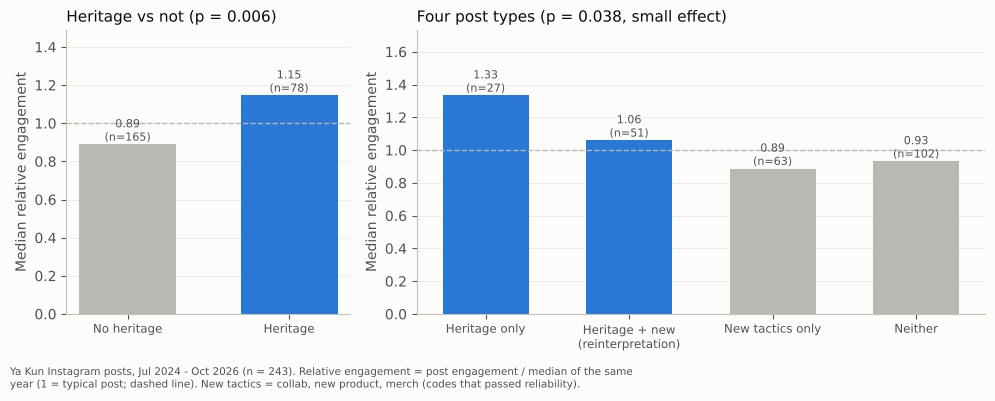

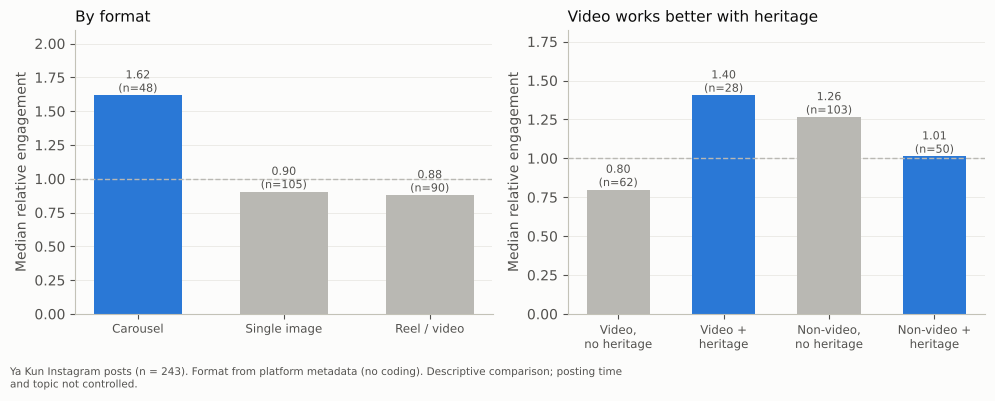

In [48]:
# Figure 1: heritage vs not, and the four post types (RQ1)
order = ["Heritage only", "Heritage + novelty", "Novelty only", "Neither"]
lab4 = ["Heritage only", "Heritage + new\n(reinterpretation)", "New tactics only", "Neither"]
g = R1.groupby("type").rel.agg(["median", "size"]).reindex(order); h = R1.groupby("Hbin").rel.agg(["median", "size"])
p_kw = kruskal(*[gg.rel for _, gg in R1.groupby("type")]).pvalue; p_h = mwu_p(R1[R1.Hbin == 1].rel, R1[R1.Hbin == 0].rel)
fig, axs = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 2]})
med_bars(axs[0], ["No heritage", "Heritage"], h["median"].values, h["size"].values, [GREY, BLUE], f"Heritage vs not (p = {p_h:.3f})")
med_bars(axs[1], lab4, g["median"].values, g["size"].values, [BLUE, BLUE, GREY, GREY], f"Four post types (p = {p_kw:.3f}, small effect)")
finish(fig, axs, "fig1_rq1_types.png", "Ya Kun Instagram posts, Jul 2024 - Oct 2026 (n = 243). Relative engagement = post engagement / median of the same year (1 = typical post; dashed line). New tactics = collab, new product, merch (codes that passed reliability).")

# Figure 2: format, and video with / without heritage (RQ1)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
f2 = R1.groupby("format").rel.agg(["median", "size"]).reindex(["carousel", "image", "reel_video"])
med_bars(axs[0], ["Carousel", "Single image", "Reel / video"], f2["median"].values, f2["size"].values, [BLUE, GREY, GREY], "By format")
R1["is_video"] = R1.format.eq("reel_video"); xv = R1.groupby(["is_video", "Hbin"]).rel.agg(["median", "size"])
idx = [(True, 0), (True, 1), (False, 0), (False, 1)]
med_bars(axs[1], ["Video,\nno heritage", "Video +\nheritage", "Non-video,\nno heritage", "Non-video +\nheritage"],
         [xv.loc[i, "median"] for i in idx], [xv.loc[i, "size"] for i in idx], [GREY, BLUE, GREY, BLUE], "Video works better with heritage")
finish(fig, axs, "fig2_rq1_format.png", "Ya Kun Instagram posts (n = 243). Format from platform metadata (no coding). Descriptive comparison; posting time and topic not controlled.")

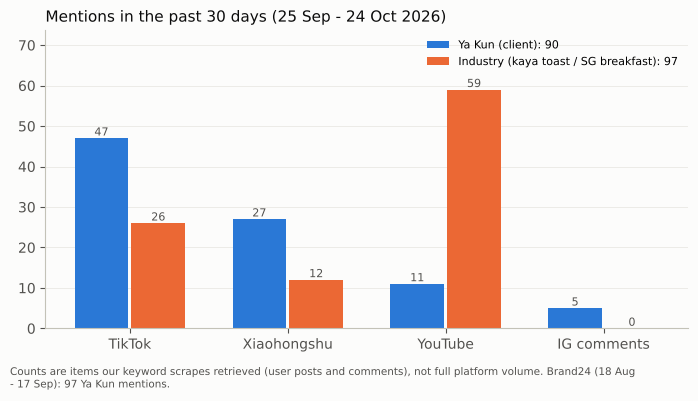

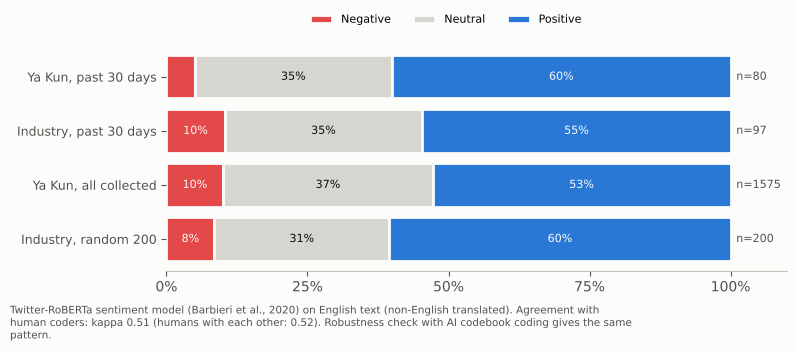

In [49]:
# Figure 3: mentions in the past 30 days by platform (Step 4)
pm = {"M11 YouTube comments": "YouTube", "M11 YouTube videos": "YouTube", "M4 official-post comments": "IG comments", "M5 TikTok UGC": "TikTok", "M6 Xiaohongshu notes": "Xiaohongshu"}
vt = pd.crosstab(W30.dataset.map(pm), W30.grp).reindex(["TikTok", "Xiaohongshu", "YouTube", "IG comments"]).fillna(0)
fig, ax = plt.subplots(figsize=(7, 4)); x = np.arange(len(vt))
for i, (grp, c_, lab) in enumerate([("client", BLUE, "Ya Kun (client)"), ("industry", ORANGE, "Industry (kaya toast / SG breakfast)")]):
    bb = ax.bar(x + (i - 0.5) * 0.36, vt[grp], 0.34, color=c_, label=f"{lab}: {int(vt[grp].sum())}")
    for r, v in zip(bb, vt[grp]): ax.text(r.get_x() + r.get_width() / 2, v, int(v), ha="center", va="bottom", fontsize=8, color=SUB)
ax.set_ylim(0, vt.values.max() * 1.25); ax.set_xticks(x, vt.index); ax.legend(frameon=False, fontsize=8)
ax.set_title("Mentions in the past 30 days (25 Sep - 24 Oct 2026)", loc="left", fontsize=11, color=TX)
finish(fig, [ax], "fig3_volume_30d.png", "Counts are items our keyword scrapes retrieved (user posts and comments), not full platform volume. Brand24 (18 Aug - 17 Sep): 97 Ya Kun mentions.")

# Figure 4: sentiment, Twitter-RoBERTa (Step 4)
rows4 = [("Ya Kun, past 30 days", yk30s), ("Industry, past 30 days", IND[IND.in30].uid), ("Ya Kun, all collected", R2.uid), ("Industry, random 200", IND[~IND.in30].uid)]
cols4 = {"N": ("Negative", "#e34948"), "U": ("Neutral", "#d6d5d0"), "P": ("Positive", BLUE)}
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (lab, uids) in enumerate(rows4[::-1]):
    sh_ = uids.map(ROB).value_counts(normalize=True) * 100; left = 0
    for c_ in "NUP":
        v = sh_.get(c_, 0); ax.barh(i, v, left=left, color=cols4[c_][1], edgecolor="#fcfcfb", lw=2, label=cols4[c_][0] if i == 0 else None)
        if v >= 6: ax.text(left + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="#fcfcfb" if c_ != "U" else TX)
        left += v
    ax.text(101, i, f"n={len(uids)}", va="center", fontsize=8, color=SUB)
ax.set_yticks(range(4), [l for l, _ in rows4[::-1]], fontsize=9); ax.set_xlim(0, 110); ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, 1.18)); ax.spines["left"].set_visible(False)
finish(fig, [], "fig4_sentiment.png", "Twitter-RoBERTa sentiment model (Barbieri et al., 2020) on English text (non-English translated). Agreement with human coders: kappa 0.51 (humans with each other: 0.52). Robustness check with AI codebook coding gives the same pattern.")

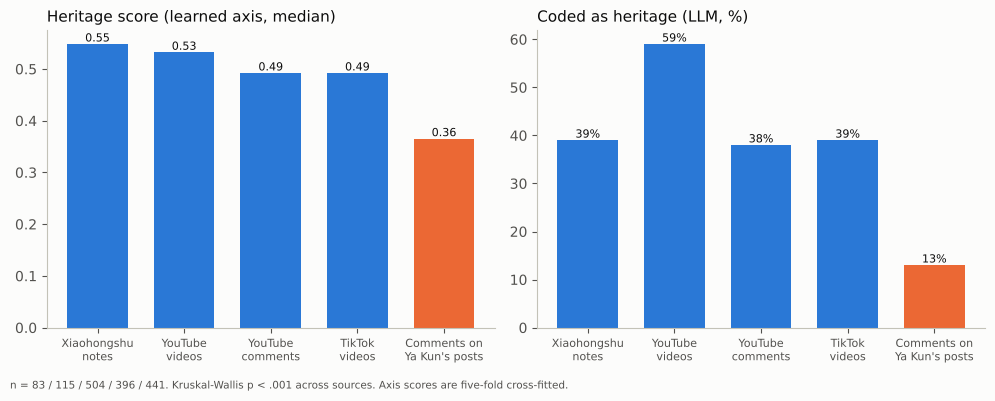

In [50]:
# Figure 5: heritage in user content by source (RQ2)
order5 = ["M6 Xiaohongshu notes", "M11 YouTube videos", "M11 YouTube comments", "M5 TikTok UGC", "M4 official-post comments"]
lab5 = ["Xiaohongshu\nnotes", "YouTube\nvideos", "YouTube\ncomments", "TikTok\nvideos", "Comments on\nYa Kun's posts"]
s5 = SRC.reindex(order5); fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, colname, title, fmt in [(axs[0], "axis_median", "Heritage score (learned axis, median)", "{:.2f}"), (axs[1], "llm_pct", "Coded as heritage (LLM, %)", "{:.0f}%")]:
    bb = ax.bar(range(5), s5[colname], 0.7, color=[BLUE] * 4 + [ORANGE])
    for r, v in zip(bb, s5[colname]): ax.text(r.get_x() + r.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=8, color=TX)
    ax.set_xticks(range(5), lab5, fontsize=8); ax.set_title(title, loc="left", fontsize=11, color=TX)
finish(fig, [], "fig5_rq2_sources.png", f"n = {' / '.join(str(int(n)) for n in s5.n)}. Kruskal-Wallis p < .001 across sources. Axis scores are five-fold cross-fitted.")

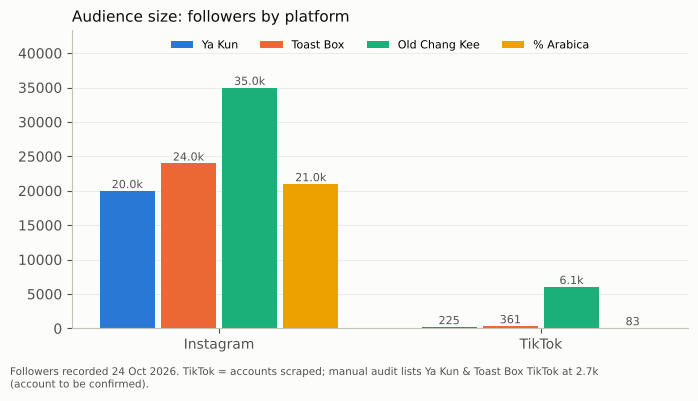

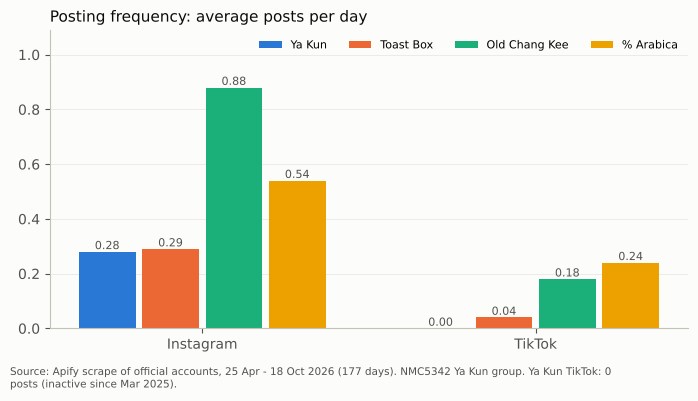

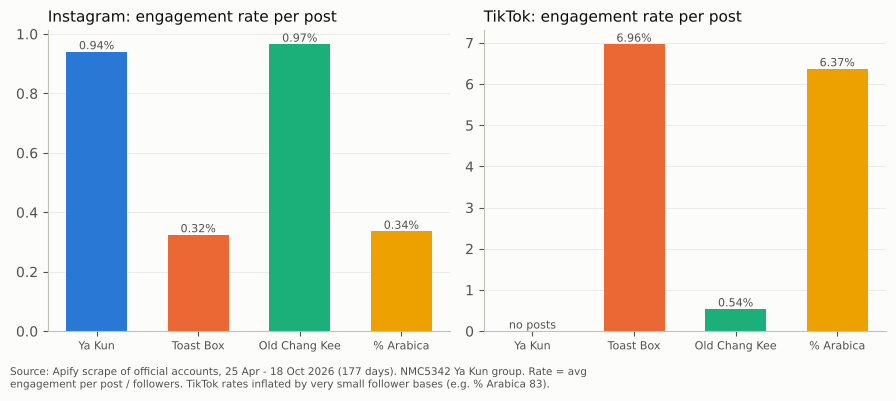

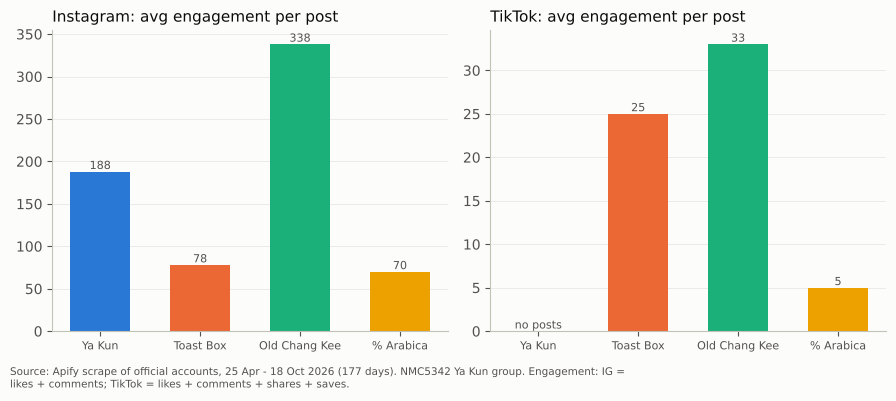

In [51]:
# Figures 6-8 and B1: Step 1 / Step 5 metrics by brand and platform
MET = T4.reset_index().rename(columns={"posts/day": "avg_posts_per_day", "eng/post": "avg_engagement_per_post"})
MET["engagement_rate_per_post"] = MET["rate_raw"]; MET["followers"] = [FOL[(b_, pf)] for b_, pf in zip(MET.brand, MET.platform)]
SRCNOTE = "Source: Apify scrape of official accounts, 25 Apr - 18 Oct 2026 (177 days). NMC5342 Ya Kun group."
def getv(b_, pf, metric):
    v = MET[(MET.brand == b_) & (MET.platform == pf)][metric]; return 0 if v.empty or pd.isna(v.iloc[0]) else v.iloc[0]
def grouped(ax, metric, fmt, title):
    x = np.arange(2); w = 0.19
    for i, b_ in enumerate(BR):
        vals = [getv(b_, pf, metric) for pf in ["Instagram", "TikTok"]]
        bb = ax.bar(x + (i - 1.5) * w, vals, w - 0.02, color=COL[b_], label=b_)
        for r, v in zip(bb, vals): ax.text(r.get_x() + r.get_width() / 2, r.get_height(), fmt(v), ha="center", va="bottom", fontsize=8, color=SUB)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.18); ax.set_xticks(x, ["Instagram", "TikTok"]); ax.set_title(title, loc="left", color=TX, fontsize=11)
fig, ax = plt.subplots(figsize=(7, 4)); grouped(ax, "followers", lambda v: f"{v/1000:.1f}k" if v >= 1000 else f"{v:.0f}", "Audience size: followers by platform")
ax.legend(frameon=False, ncol=4, loc="upper center", fontsize=8)
finish(fig, [ax], "fig6_followers.png", "Followers recorded 24 Oct 2026. TikTok = accounts scraped; manual audit lists Ya Kun & Toast Box TikTok at 2.7k (account to be confirmed).")
fig, ax = plt.subplots(figsize=(7, 4)); grouped(ax, "avg_posts_per_day", lambda v: f"{v:.2f}", "Posting frequency: average posts per day"); ax.legend(frameon=False, ncol=4, fontsize=8)
finish(fig, [ax], "fig7_posts_per_day.png", SRCNOTE + " Ya Kun TikTok: 0 posts (inactive since Mar 2025).")
for metric, name, title, fmt, note in [
        ("engagement_rate_per_post", "fig8_eng_rate.png", "engagement rate per post", lambda v: f"{v*100:.2f}%", " Rate = avg engagement per post / followers. TikTok rates inflated by very small follower bases (e.g. % Arabica 83)."),
        ("avg_engagement_per_post", "figB1_eng_per_post.png", "avg engagement per post", lambda v: f"{v:.0f}", " Engagement: IG = likes + comments; TikTok = likes + comments + shares + saves.")]:
    fig, axs = plt.subplots(1, 2, figsize=(9, 4))
    for ax, pf in zip(axs, ["Instagram", "TikTok"]):
        vals = [getv(b_, pf, metric) for b_ in BR]; mult = 100 if "rate" in metric else 1
        bb = ax.bar(range(4), [v * mult for v in vals], 0.6, color=[COL[b_] for b_ in BR])
        for r, v in zip(bb, vals): ax.text(r.get_x() + r.get_width() / 2, r.get_height(), fmt(v) if v else "no posts", ha="center", va="bottom", fontsize=8, color=SUB)
        ax.set_xticks(range(4), BR, fontsize=8); ax.set_title(f"{pf}: {title}", loc="left", fontsize=11, color=TX)
    finish(fig, axs, name, SRCNOTE + note)

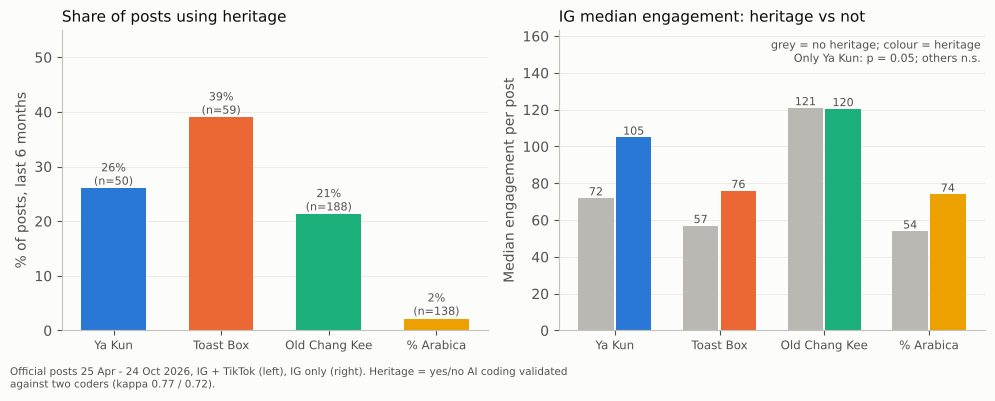

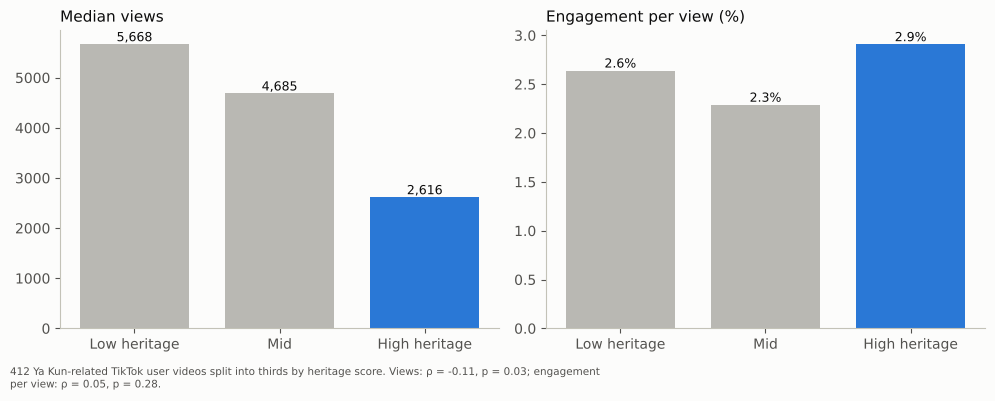

In [52]:
# Figure 9: heritage share and IG engagement by brand (RQ3)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
shv = [W6[W6.brand == b_].Hbin.mean() * 100 for b_ in BR]; nsv = [len(W6[W6.brand == b_]) for b_ in BR]
bb = axs[0].bar(range(4), shv, 0.6, color=[COL[b_] for b_ in BR])
for r, v, n in zip(bb, shv, nsv): axs[0].text(r.get_x() + r.get_width() / 2, v, f"{v:.0f}%\n(n={n})", ha="center", va="bottom", fontsize=8, color=SUB)
axs[0].set_xticks(range(4), BR, fontsize=8.5); axs[0].set_ylim(0, 55); axs[0].set_title("Share of posts using heritage", loc="left", fontsize=11, color=TX); axs[0].set_ylabel("% of posts, last 6 months")
wi = W6[W6.platform == "Instagram"]; xb = np.arange(4)
for j, hv in enumerate([0, 1]):
    vals = [wi[(wi.brand == b_) & (wi.Hbin == hv)].engagement.median() for b_ in BR]
    bb = axs[1].bar(xb + (j - 0.5) * 0.36, vals, 0.34, color=[GREY] * 4 if hv == 0 else [COL[b_] for b_ in BR])
    for r, v in zip(bb, vals): axs[1].text(r.get_x() + r.get_width() / 2, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color=SUB)
axs[1].set_xticks(xb, BR, fontsize=8.5); axs[1].set_title("IG median engagement: heritage vs not", loc="left", fontsize=11, color=TX); axs[1].set_ylabel("Median engagement per post")
axs[1].text(0.99, 0.97, "grey = no heritage; colour = heritage\nOnly Ya Kun: p = 0.05; others n.s.", transform=axs[1].transAxes, ha="right", va="top", fontsize=8, color=SUB)
axs[1].set_ylim(0, wi.groupby(["brand", "Hbin"]).engagement.median().max() * 1.35)
finish(fig, axs, "fig9_rq3_heritage.png", "Official posts 25 Apr - 24 Oct 2026, IG + TikTok (left), IG only (right). Heritage = yes/no AI coding validated against two coders (kappa 0.77 / 0.72).")

# Figure 10: TikTok views and engagement per view by heritage third (RQ4)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, colname, title, fmt, mult in [(axs[0], "views_median", "Median views", "{:,.0f}", 1), (axs[1], "epv_median", "Engagement per view (%)", "{:.1f}%", 100)]:
    vals = TER[colname].values * mult; bb = ax.bar(["Low heritage", "Mid", "High heritage"], vals, 0.75, color=[GREY, GREY, BLUE])
    for r, v in zip(bb, vals): ax.text(r.get_x() + r.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=9, color=TX)
    ax.set_title(title, loc="left", fontsize=11, color=TX)
finish(fig, [], "fig10_rq4_tiktok.png", f"412 Ya Kun-related TikTok user videos split into thirds by heritage score. Views: ρ = {rv.correlation:.2f}, p = {rv.pvalue:.2f}; engagement per view: ρ = {re_.correlation:.2f}, p = {re_.pvalue:.2f}.")

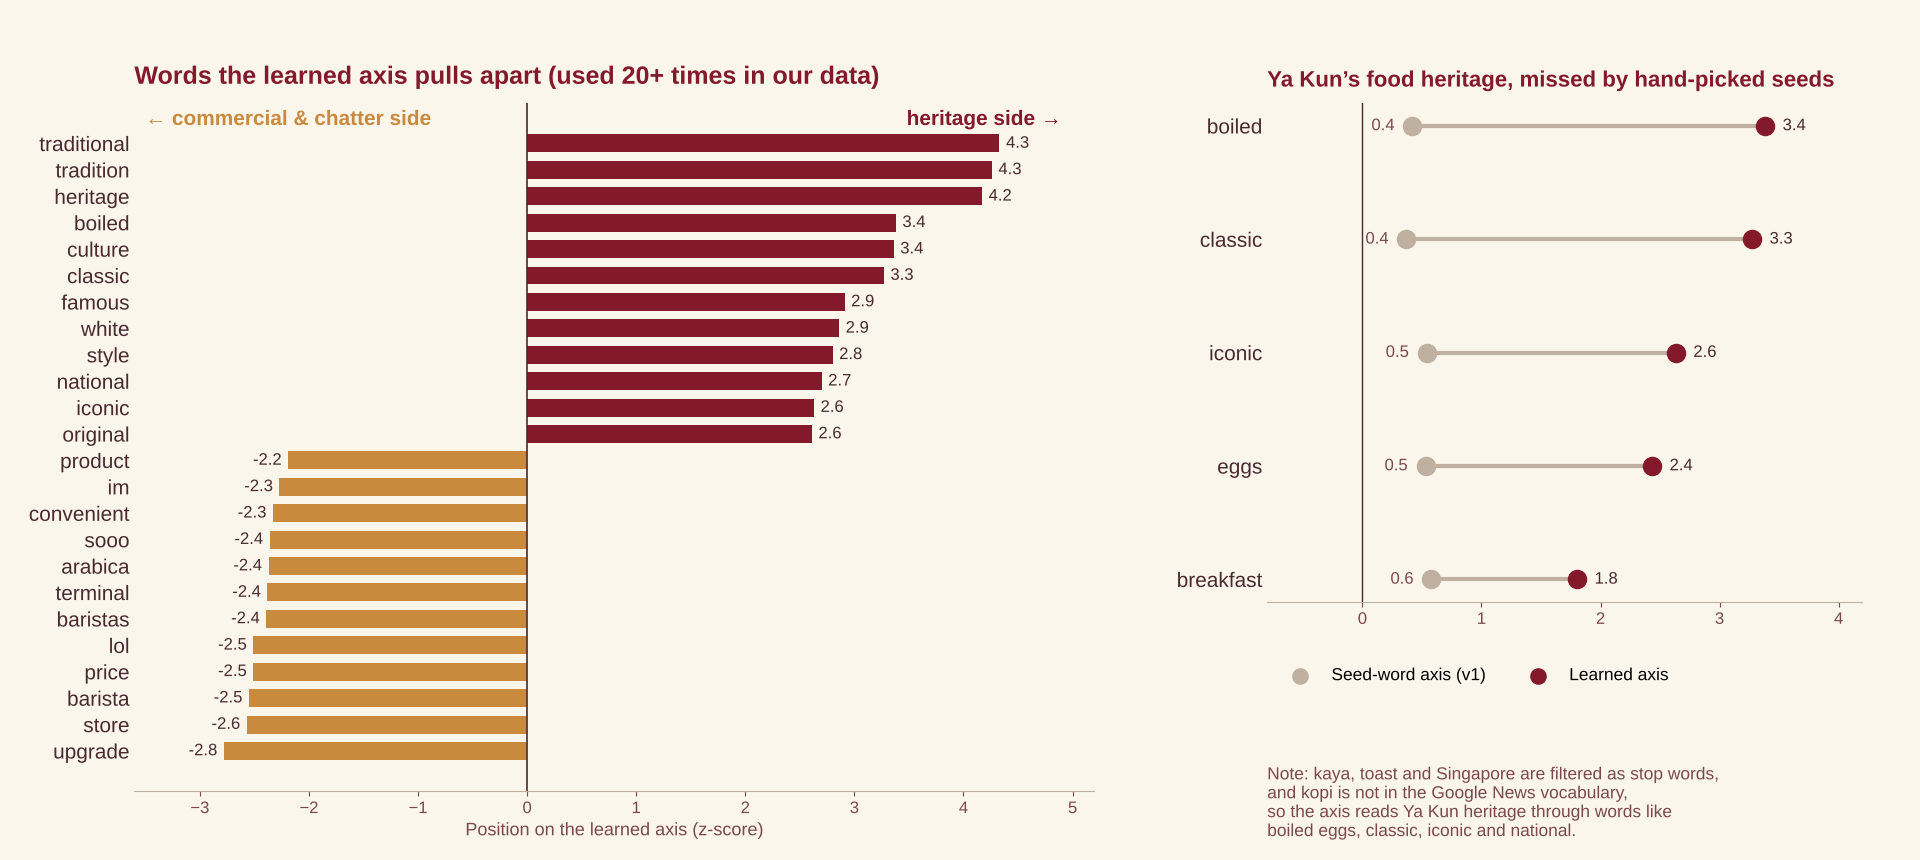

['fig10_rq4_tiktok.png', 'fig1_rq1_types.png', 'fig2_rq1_format.png', 'fig3_volume_30d.png', 'fig4_sentiment.png', 'fig5_rq2_sources.png', 'fig6_followers.png', 'fig7_posts_per_day.png', 'fig8_eng_rate.png', 'fig9_rq3_heritage.png', 'figB1_eng_per_post.png']


In [53]:
# Figure B2: word positions on the learned axis vs the seed-word axis.
# Drawn from the Google News word vectors (scripts/analysis/rq_1103/heritage_axis_words_1106.py), so the saved image is shown;
# the word positions themselves are in analysis_outputs/heritage轴_学出的词位置_1106.csv (printed in Part 4.2).
display(Image(filename=str(AO / "charts_1103" / "heritage轴_学出的词位置图_1106.png"), width=900))
print(sorted(os.listdir(OUT / "figures")))

## 12 Summary of checks against the report
Notes on numbers that need care:
- **Tourist-orientation gate.** κ 0.73 is for *tourist-oriented vs not* on the 56 user posts both members coded (brand / media posts removed). The share judgeable recomputed from the returned sheets is 63% (member 1) and 79% (member 2), mean 71%; the report's 64% could not be reproduced. Both values pass the 60% gate.
- **Topics.** The report's NMF run used 2,160 documents; after later translations the same filter gives 2,249. The notebook reruns NMF on the report's 2,160 documents.
- **RoBERTa 30-day shares** use the 80 Ya Kun mentions that are in the RQ2 base (90 mentions in total).

In [54]:
CK = pd.DataFrame(CHECKS, columns=["item", "notebook", "report", "match"])
print(f"{(CK.match == '✓').sum()} of {len(CK)} report numbers reproduced")
print(CK[CK.match == "✗"].to_string(index=False) if (CK.match == "✗").any() else "All checks match.")
CK.to_csv(OUT / "report_number_checks.csv", index=False, encoding="utf-8-sig")

141 of 142 report numbers reproduced
                                                     item  notebook  report match
Tourist orientation: share judgeable (mean of two coders)      0.71    0.64     ✗


## Appendix: helper scripts not repeated here
These scripts in `scripts/` produced files for the coders and do not affect any number above:
- `build_coding_sheets.py`, `analysis/build_coding_v2.py`: draw the reliability samples (seed 5342) and write one Excel coding sheet per coder.
- `analysis/rq_1103/s35_sheet.py`, `tiebreak.py`: list the cells where the two top-post coders disagreed; the final code is always one of the two coders' answers (enforced by an `assert`).
- `fill_step5_template.py`: fills the course's Step 5 Canvas template with the metrics in Part 5.
- `xhs_translations.py`, `add_translations.py`: store the LLM translations and merge them as `text_en`.
- `xhs_mediacrawler.command`: an attempt to fetch full Xiaohongshu text; not used in the analysis.